# 1. اختيار المشكلة

بعد الاطلاع على المشاكل الثلاث المقترحة، اخترت مشكلة التوصيل
(Food Delivery)

واللي تركز على معرفة العوامل المؤثرة في وقت وصول الطلبات.

اخترت هذه المشكلة مبدئيًا لأنها من المشاكل اللي أواجهها بشكل شخصي وألاحظ تكرارها كثير، وحسيت أن فكرتها واضحة وسهل أشرحها وأفهم الهدف منها.

لكن قبل اعتماد الاختيار بشكل نهائي، اطلعت على البيانات وقارنتها بالخيارات الثانية، وبعدها تأكدت أن هذا المشروع مناسب لي وأقدر أشتغل عليه خلال الأسبوع.

# 2. فهم المشكلة

### 1. من هو العميل؟

العميل هو شركة توصيل طعام عندها عدد كبير من الطلبات، وتواجه مشكلة في تحديد وقت وصول الطلبات بشكل دقيق، وهذا يسبب تأخير بعض الطلبات وعدم رضا العملاء.

### 2. وش المشكلة اللي نحاول نحلها؟

نحاول نفهم الأسباب اللي تؤثر على وقت التوصيل، مثل الطقس والازدحام والمسافة، ونشوف كيف نقدر نحسن الوقت المتوقع لوصول الطلب للعميل.

### 3. ما هو الـ Target؟

هو `Time_taken(min)`

 وهو الوقت اللي استغرقه توصيل الطلب بالدقائق.

نوعه رقمي (Numerical)،

لذلك المشكلة تعتبر من نوع `Regression`

لأننا نحاول نتوقع قيمة رقمية.

### 4. مين بيستخدم المنتج؟

- العميل: عشان يعرف الوقت المتوقع لوصول طلبه.
- مدير التشغيل: عشان يتابع أوقات التوصيل ويعرف أسباب التأخير.

### 5. الأسئلة اللي بنحاول نجاوب عنها خلال المشروع

1. هل الطقس يؤثر على وقت التوصيل؟
2. هل الازدحام يسبب تأخير الطلبات؟
3. هل المسافة لها علاقة بوقت التوصيل؟
4. هل عمر المندوب أو تقييمه يؤثر على سرعة التوصيل؟
5. وش أكثر العوامل ارتباطًا بوقت التوصيل؟

# 3. أول نظرة على البيانات

في هذا القسم بنبدأ نستكشف البيانات ونتعرف على حجمها والأعمدة الموجودة فيها، ونتأكد من أنواع البيانات والقيم المفقودة قبل ما نبدأ التنظيف.

In [187]:
# استيراد المكتبة
import pandas as pd

# قراءة البيانات
df = pd.read_csv('train.csv')

# عرض أول 5 صفوف
df.head()

,ID,Delivery_person_ID,Delivery_person_Age,Delivery_person_Ratings,Restaurant_latitude,Restaurant_longitude,Delivery_location_latitude,Delivery_location_longitude,Order_Date,Time_Orderd,Time_Order_picked,Weatherconditions,Road_traffic_density,Vehicle_condition,Type_of_order,Type_of_vehicle,multiple_deliveries,Festival,City,Time_taken(min)
0,0x4607,INDORES13DEL02,37,4.9,22.745049,75.892471,22.765049,75.912471,19-03-2022,11:30:00,11:45:00,conditions Sunny,High,2,Snack,motorcycle,0,No,Urban,(min) 24
1,0xb379,BANGRES18DEL02,34,4.5,12.913041,77.683237,13.043041,77.813237,25-03-2022,19:45:00,19:50:00,conditions Stormy,Jam,2,Snack,scooter,1,No,Metropolitian,(min) 33
2,0x5d6d,BANGRES19DEL01,23,4.4,12.914264,77.678400,12.924264,77.688400,19-03-2022,08:30:00,08:45:00,conditions Sandstorms,Low,0,Drinks,motorcycle,1,No,Urban,(min) 26
3,0x7a6a,COIMBRES13DEL02,38,4.7,11.003669,76.976494,11.053669,77.026494,05-04-2022,18:00:00,18:10:00,conditions Sunny,Medium,0,Buffet,motorcycle,1,No,Metropolitian,(min) 21
4,0x70a2,CHENRES12DEL01,32,4.6,12.972793,80.249982,13.012793,80.289982,26-03-2022,13:30:00,13:45:00,conditions Cloudy,High,1,Snack,scooter,1,No,Metropolitian,(min) 30


In [188]:
# معرفة حجم البيانات
df.shape

(45593, 20)

- 45,593 صفًا (Rows):

 كل صف يمثل طلب توصيل

- 20 عمودًا (Columns):

 كل عمود يمثل معلومة عن الطلب، مثل الطقس أو المندوب أو وقت التوصيل.

وهذا يطابق حجم البيانات المذكور في ملف المهمة.

In [189]:
# عرض معلومات الأعمدة وأنواع البيانات
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45593 entries, 0 to 45592
Data columns (total 20 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   ID                           45593 non-null  object 
 1   Delivery_person_ID           45593 non-null  object 
 2   Delivery_person_Age          45593 non-null  object 
 3   Delivery_person_Ratings      45593 non-null  object 
 4   Restaurant_latitude          45593 non-null  float64
 5   Restaurant_longitude         45593 non-null  float64
 6   Delivery_location_latitude   45593 non-null  float64
 7   Delivery_location_longitude  45593 non-null  float64
 8   Order_Date                   45593 non-null  object 
 9   Time_Orderd                  45593 non-null  object 
 10  Time_Order_picked            45593 non-null  object 
 11  Weatherconditions            45593 non-null  object 
 12  Road_traffic_density         45593 non-null  object 
 13  Vehicle_conditio

## انواع البيانات:

| النوع | العدد | معناه |
|---|---:|---|
| `object` | 15 | نصوص أو قيم مخزنة كنصوص |
| `float64` | 4 | أرقام عشرية |
| `int64` | 1 | أرقام صحيحة |

In [190]:
# حساب القيم المفقودة في كل عمود
df.isnull().sum()

,0
ID,0
Delivery_person_ID,0
Delivery_person_Age,0
Delivery_person_Ratings,0
Restaurant_latitude,0
Restaurant_longitude,0
Delivery_location_latitude,0
Delivery_location_longitude,0
Order_Date,0
Time_Orderd,0


- لا توجد قيم مفقودة اكتشفها isnull()
- نحتاج نفحص القيم النصية للتأكد من عدم وجود قيم مفقودة مكتوبة كنص

In [191]:
# حساب عدد الصفوف المكررة
df.duplicated().sum()

np.int64(0)

لا نعتبر نتيجة الصفر دليلًا على خلو البيانات من جميع المشاكل

In [192]:
# عرض الإحصائيات الوصفية للأعمدة الرقمية
df.describe()

,Restaurant_latitude,Restaurant_longitude,Delivery_location_latitude,Delivery_location_longitude,Vehicle_condition
count,45593.000000,45593.000000,45593.000000,45593.000000,45593.000000
mean,17.017729,70.231332,17.465186,70.845702,1.023359
std,8.185109,22.883647,7.335122,21.118812,0.839065
min,-30.905562,-88.366217,0.010000,0.010000,0.000000
25%,12.933284,73.170000,12.988453,73.280000,0.000000
50%,18.546947,75.898497,18.633934,76.002574,1.000000
75%,22.728163,78.044095,22.785049,78.107044,2.000000
max,30.914057,88.433452,31.054057,88.563452,3.000000


In [193]:
# عرض إحصائيات الأعمدة النصية
df.describe(include='object')

,ID,Delivery_person_ID,Delivery_person_Age,Delivery_person_Ratings,Order_Date,Time_Orderd,Time_Order_picked,Weatherconditions,Road_traffic_density,Type_of_order,Type_of_vehicle,multiple_deliveries,Festival,City,Time_taken(min)
count,45593,45593,45593,45593,45593,45593,45593,45593,45593,45593,45593,45593,45593,45593,45593
unique,45593,1320,23,29,44,177,193,7,5,4,4,5,3,4,45
top,0x4607,PUNERES01DEL01,35,4.8,15-03-2022,NaN,21:30:00,conditions Fog,Low,Snack,motorcycle,1,No,Metropolitian,(min) 26
freq,1,67,2262,7148,1192,1731,496,7654,15477,11533,26435,28159,44469,34093,2123


هذا الأمر يعرض لنا:

- count: عدد القيم.
- unique: عدد القيم المختلفة.
- top: أكثر قيمة تكرارًا.
- freq: عدد مرات تكرارها.

 الخطوة التالية عشان نتأكد من أنواع القيم الموجودة، ونلاحظ إذا فيه اختلافات في الكتابة أو قيم غير متوقعة.

In [194]:
# عرض القيم المختلفة في الأعمدة النصية
for col in df.select_dtypes(include='object').columns:
    print(col)
    print(df[col].unique()[:15])
    print('----------------')

ID
['0x4607 ' '0xb379 ' '0x5d6d ' '0x7a6a ' '0x70a2 ' '0x9bb4 ' '0x95b4 '
 '0x9eb2 ' '0x1102 ' '0xcdcd ' '0xd987 ' '0x2784 ' '0xc8b6 ' '0xdb64 '
 '0x3af3 ']
----------------
Delivery_person_ID
['INDORES13DEL02 ' 'BANGRES18DEL02 ' 'BANGRES19DEL01 ' 'COIMBRES13DEL02 '
 'CHENRES12DEL01 ' 'HYDRES09DEL03 ' 'RANCHIRES15DEL01 ' 'MYSRES15DEL02 '
 'HYDRES05DEL02 ' 'DEHRES17DEL01 ' 'KOCRES16DEL01 ' 'PUNERES13DEL03 '
 'LUDHRES15DEL02 ' 'KNPRES14DEL02 ' 'MUMRES15DEL03 ']
----------------
Delivery_person_Age
['37' '34' '23' '38' '32' '22' '33' '35' '36' '21' '24' '29' '25' '31'
 '27']
----------------
Delivery_person_Ratings
['4.9' '4.5' '4.4' '4.7' '4.6' '4.8' '4.2' '4.3' '4' '4.1' '5' '3.5'
 'NaN ' '3.8' '3.9']
----------------
Order_Date
['19-03-2022' '25-03-2022' '05-04-2022' '26-03-2022' '11-03-2022'
 '04-03-2022' '14-03-2022' '20-03-2022' '12-02-2022' '13-02-2022'
 '14-02-2022' '02-04-2022' '01-03-2022' '16-03-2022' '15-02-2022']
----------------
Time_Orderd
['11:30:00' '19:45:00' '08:30:00' 


لاحظت وجود مسافات زائدة في بعض القيم، وقيم مفقودة مكتوبة كنصوص، بالإضافة إلى أعمدة رقمية مخزنة كنصوص.

كذلك يحتاج عمود الطقس ووقت التوصيل إلى معالجة النصوص الإضافية.

براجع هذه المشاكل في مرحلة تنظيف البيانات.

In [195]:
# حساب القيم المكتوبة كنص NaN
for col in df.columns:
    count = df[col].astype(str).str.strip().eq('NaN').sum()
    if count > 0:
        print(col, ':', count)

Delivery_person_Age : 1854
Delivery_person_Ratings : 1908
Time_Orderd : 1731
Road_traffic_density : 601
multiple_deliveries : 993
Festival : 228
City : 1200


## ملاحظات:

بعد فحص القيم المكتوبة كنص `NaN`،

اكتشفت وجود قيم مفقودة في 7 أعمدة،

وكان أكبر عدد منها في عمود:

 `Delivery_person_Ratings`

بعدد 1,908 قيمة


هذا يوضح أن البيانات تحتوي على قيم مفقودة لم تظهر في الفحص الأول، لأنها كانت مكتوبة كنصوص.

### تحليل وقت التوصيل (Target)

لاحظت أن عمود `Time_taken(min)` يحتوي على الأرقام مع النص

المشكلة أن الأرقام مخزنة مع النص (min)

وبالتالي ما نقدر نستخدمها مباشرة في العمليات الحسابية والرسومات.

في الكود التالي بستخرج الأرقام واحفظها في متغير جديد بدون ما تتغير البيانات الأصلية.

In [196]:
# استخراج وقت التوصيل كأرقام
time_taken = df['Time_taken(min)'].str.replace('(min) ', '', regex=False).astype(int)

# عرض أول 5 قيم
time_taken.head()

,Time_taken(min)
0,24
1,33
2,26
3,21
4,30


تم استخراج الأرقام من عمود وقت التوصيل وتحويلها إلى نوع رقمي، وبكذا أصبح العمود جاهزًا للتحليل وحساب الإحصائيات.

In [197]:
# عرض إحصائيات وقت التوصيل
time_taken.describe()

,Time_taken(min)
count,45593.000000
mean,26.294607
std,9.383806
min,10.000000
25%,19.000000
50%,26.000000
75%,32.000000
max,54.000000


من خلال الإحصائيات:

 لاحظت أن متوسط وقت التوصيل حوالي 26 دقيقة،

 وأقل وقت كان 10 دقائق

وأعلى وقت 54 دقيقة

 هذا يوضح وجود اختلاف في أوقات التوصيل بين الطلبات، ونحتاج نعرف العوامل اللي ممكن تكون سبب في هذا الاختلاف.

In [198]:
# فحض الاعمدة الرقمية والتأكد من القيم الموجودة فيها قبل ما اقرر طريقة التعامل معها

for col in ['Delivery_person_Age', 'Delivery_person_Ratings', 'multiple_deliveries']:
    print(col)
    print(df[col].unique())
    print('----------------')

Delivery_person_Age
['37' '34' '23' '38' '32' '22' '33' '35' '36' '21' '24' '29' '25' '31'
 '27' '26' '20' 'NaN ' '28' '39' '30' '15' '50']
----------------
Delivery_person_Ratings
['4.9' '4.5' '4.4' '4.7' '4.6' '4.8' '4.2' '4.3' '4' '4.1' '5' '3.5'
 'NaN ' '3.8' '3.9' '3.7' '2.6' '2.5' '3.6' '3.1' '2.7' '1' '3.2' '3.3'
 '6' '3.4' '2.8' '2.9' '3']
----------------
multiple_deliveries
['0' '1' '3' 'NaN ' '2']
----------------


- توجد قيم مفقودة في الأعمدة الثلاثة.
- العمر 15 ظهر في 38 سجلًا.
- التقييم 6 ظهر في 53 سجلًا.
- قيم `multiple_deliveries` تتراوح بين 0 و3.

In [199]:
# التحقق من القيم الغير معتادة في العمر والتقييم

# عرض الأعمار الأقل من 18
print("Ages below 18:")
print(df[df['Delivery_person_Age'].astype(str).str.strip().isin(['15'])]['Delivery_person_Age'].value_counts())

# عرض التقييمات الأعلى من 5
print("Ratings above 5:")
print(df[df['Delivery_person_Ratings'].astype(str).str.strip().isin(['6'])]['Delivery_person_Ratings'].value_counts())

Ages below 18:
Delivery_person_Age
15    38
Name: count, dtype: int64
Ratings above 5:
Delivery_person_Ratings
6    53
Name: count, dtype: int64


- Age 15: ظهر في 38 سجلًا
- Rating 6: ظهر في 53 سجلًا

 القيمتان تحتاجان مراجعة قبل التنظيف.
 لأن العمر أقل من المتوقع للمندوبين، والتقييم يتجاوز النطاق المعتاد من 1 إلى 5. قررت تسجيلها للمراجعة وتأجيل التعامل معها إلى مرحلة تنظيف البيانات.

In [200]:
# فحص الإحداثيات التي تساوي 0.01
print("Delivery latitude:")
print((df['Delivery_location_latitude'] == 0.01).sum())

print("Delivery longitude:")
print((df['Delivery_location_longitude'] == 0.01).sum())

Delivery latitude:
327
Delivery longitude:
327


- 327 سجلًا تحتوي على إحداثيات توصيل بقيمة `0.01` في خط العرض والطول.
- سيتم مراجعة هذه السجلات أثناء تنظيف البيانات.

## 4. الاستكشاف والتحليل (EDA)

### توزيع وقت التوصيل

قبل دراسة العوامل المؤثرة، ببدأ بفهم توزيع أوقات التوصيل ومعرفة الأوقات الأكثر تكرارًا.

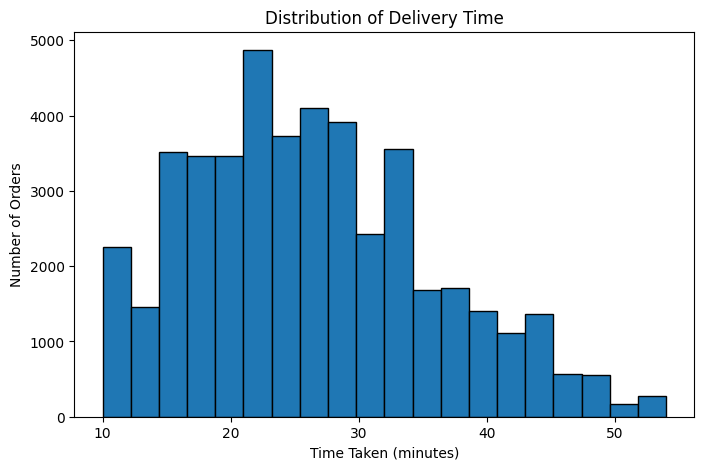

In [201]:
import matplotlib.pyplot as plt

# رسم توزيع وقت التوصيل
plt.figure(figsize=(8, 5))
plt.hist(time_taken, bins=20, edgecolor='black')

plt.title('Distribution of Delivery Time')
plt.xlabel('Time Taken (minutes)')
plt.ylabel('Number of Orders')

plt.show()

يظهر الرسم أن أغلب أوقات التوصيل تتراوح بين 15 و34 دقيقة، بينما يقل عدد الطلبات كلما زاد وقت التوصيل. وهذا يوضح وجود اختلاف في مدة التوصيل بين الطلبات.

### تأثير الطقس على وقت التوصيل

في هذا الجزء بدرس العلاقة بين حالة الطقس ووقت التوصيل، لمعرفة إذا كانت بعض الظروف الجوية مرتبطة بزيادة مدة التوصيل.

In [202]:
# تقسيم الطلبات حسب حالة الطقس، ثم احسب متوسط وقت التوصيل لكل حالة

weather_time = df.groupby('Weatherconditions')['Time_taken(min)'].apply(
    lambda x: pd.to_numeric(
        x.str.replace('(min) ', '', regex=False)
    ).mean() )

weather_time

,Time_taken(min)
Weatherconditions,
conditions Cloudy,28.917330
conditions Fog,28.916122
conditions NaN,26.545455
conditions Sandstorms,25.875517
conditions Stormy,25.870815
conditions Sunny,21.856947
conditions Windy,26.118836


- أعلى متوسط لوقت التوصيل كان في الطقس الغائم والضبابي (28.9 دقيقة).
- أقل متوسط كان في الطقس المشمس (21.9 دقيقة).
- يبدو أن الطقس قد يكون أحد العوامل المرتبطة بوقت التوصيل.

### رسم متوسط وقت التوصيل حسب الطقس

لعرض الفرق بين حالات الطقس بشكل أوضح، سأستخدم
Bar Chart لمقارنة متوسط وقت التوصيل لكل حالة.

عشان تكون المقارنة أوضح بصريًا.

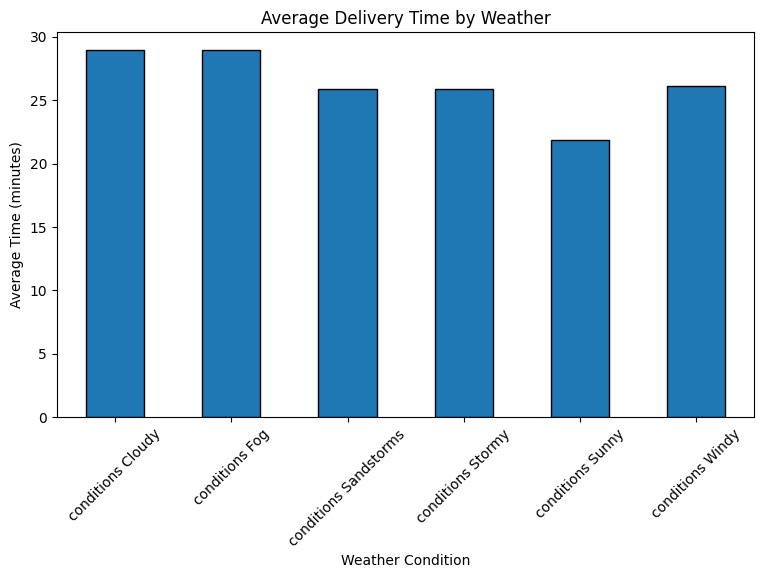

In [203]:
# رسم متوسط وقت التوصيل حسب الطقس
weather_time.drop('conditions NaN').plot(
    kind='bar',
    figsize=(9, 5),
    edgecolor='black' )

plt.title('Average Delivery Time by Weather')
plt.xlabel('Weather Condition')
plt.ylabel('Average Time (minutes)')
plt.xticks(rotation=45)
plt.show()

يوضح الرسم اختلاف متوسط وقت التوصيل حسب حالة الطقس. كان المتوسط الأعلى في الطقس الغائم والضبابي، والأقل في الطقس المشمس. وهذا يشير إلى احتمال وجود علاقة بين حالة الطقس ووقت التوصيل.

### تأثير الازدحام المروري

في هذا الجزء بدرس العلاقة بين كثافة حركة المرور ومتوسط وقت التوصيل، لمعرفة إذا كان الازدحام مرتبطًا بزيادة مدة التوصيل.

In [204]:
# حساب متوسط وقت التوصيل حسب الازدحام المروري
traffic_time = df.groupby('Road_traffic_density')['Time_taken(min)'].apply(
    lambda x: pd.to_numeric(
        x.str.replace('(min) ', '', regex=False)
    ).mean() )

traffic_time

,Time_taken(min)
Road_traffic_density,
High,27.240000
Jam,31.176624
Low,21.266977
Medium,26.699644
NaN,26.542429


- أعلى متوسط للتوصيل كان عند الازدحام الشديد (31.18 دقيقة).
- أقل متوسط كان عند الازدحام المنخفض (21.27 دقيقة).
- الفرق بينهما يقارب 10 دقائق.
- يبدو أن الازدحام المروري من العوامل المرتبطة بزيادة وقت التوصيل.

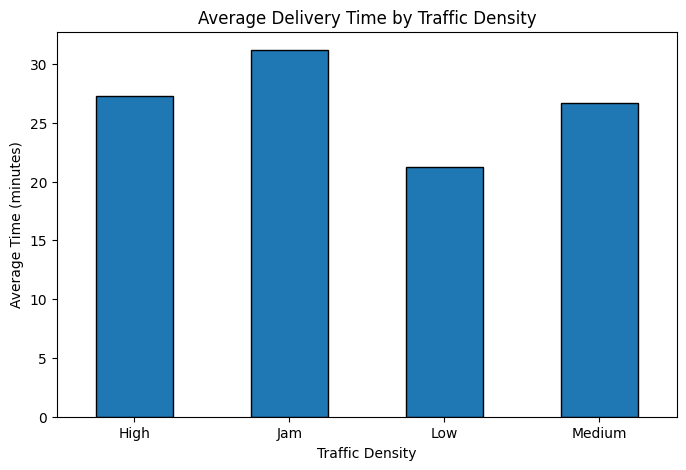

In [205]:
# إزالة المسافات من أسماء الفئات
traffic_time.index = traffic_time.index.str.strip()

# رسم متوسط وقت التوصيل حسب الازدحام
traffic_time.drop('NaN').plot(
    kind='bar',
    figsize=(8, 5),
    edgecolor='black'
)

plt.title('Average Delivery Time by Traffic Density')
plt.xlabel('Traffic Density')
plt.ylabel('Average Time (minutes)')
plt.xticks(rotation=0)
plt.show()

# rotation=0 : لأن أسماء مستويات الازدحام قصيرة، وما تحتاج تكون مائلة

يوضح الرسم أن متوسط وقت التوصيل يرتفع مع زيادة الازدحام المروري:

- Jam: أعلى متوسط لوقت التوصيل، حوالي 31 دقيقة
- High: حوالي 28 دقيقة
- Medium: حوالي 27 دقيقة
- Low: أقل متوسط، حوالي 21 دقيقة

لذلك يبدو أن الازدحام من العوامل المهمة المرتبطة بتأخير الطلبات.

### تأثير نوع المدينة

في هذا الجزء بدرس متوسط وقت التوصيل حسب نوع المدينة، لمعرفة إذا كان موقع الطلب مرتبطًا باختلاف مدة التوصيل.

In [206]:
# حساب متوسط وقت التوصيل حسب نوع المدينة
city_time = df.groupby('City')['Time_taken(min)'].apply(
    lambda x: pd.to_numeric(
        x.str.replace('(min) ', '', regex=False)
    ).mean()
)

city_time

,Time_taken(min)
City,
Metropolitian,27.315226
NaN,22.058333
Semi-Urban,49.731707
Urban,22.984017


- سجلت فئة `Semi-Urban` أعلى متوسط لوقت التوصيل (49.73 دقيقة).
- سجلت فئة `Urban` أقل متوسط (22.98 دقيقة).
- نحتاج التحقق من عدد الطلبات في كل فئة قبل اعتماد الاستنتاج.

In [207]:
# حساب عدد الطلبات في كل نوع مدينة
df['City'].value_counts()

,count
City,
Metropolitian,34093
Urban,10136
NaN,1200
Semi-Urban,164


- سجلت `Semi-Urban` أعلى متوسط للتوصيل (49.73 دقيقة)، لكن عدد طلباتها 164 فقط.
- سجلت `Urban` أقل متوسط (22.98 دقيقة).
- نحتاج التعامل بحذر مع نتيجة `Semi-Urban` بسبب قلة عدد الطلبات.

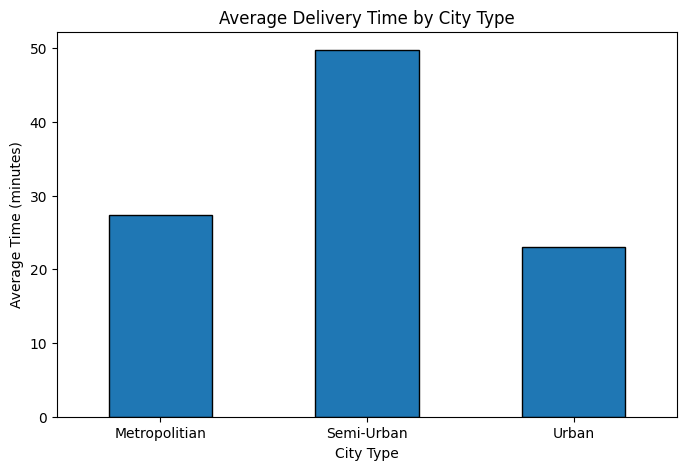

In [208]:
# إزالة المسافات من أسماء المدن
city_time.index = city_time.index.str.strip()

# رسم متوسط وقت التوصيل حسب المدينة
city_time.drop('NaN').plot(
    kind='bar',
    figsize=(8, 5),
    edgecolor='black'
)

plt.title('Average Delivery Time by City Type')
plt.xlabel('City Type')
plt.ylabel('Average Time (minutes)')
plt.xticks(rotation=0)
plt.show()

يوضح الرسم اختلاف متوسط وقت التوصيل بين أنواع المدن. سجلت Semi-Urban أعلى متوسط بحوالي 50 دقيقة، لكن عدد طلباتها قليل مقارنة بباقي المدن (164 طلبًا)، لذلك نحتاج الحذر عند تفسير هذه النتيجة.

### مراجعة خطة التحليل
 إلى الان تم تحليل:

 | التحليل | النتيجة |
|---|---|
| توزيع وقت التوصيل | أغلب الطلبات بين 15 و34 دقيقة |
| الطقس | الغائم والضبابي سجّلا أعلى متوسط |
| الازدحام | الازدحام الشديد ارتبط بأعلى متوسط |
| نوع المدينة | `Semi-Urban` أعلى متوسط، لكن عدد طلباتها قليل |


بعد الانتهاء من تحليل توزيع وقت التوصيل وتأثير الطقس والازدحام ونوع المدينة، قررت التوقف مؤقتًا عن إضافة رسوم بيانية جديدة ومراجعة التحليلات التي تم تنفيذها.

لاحظت أن بعض التحليلات تعتمد على نفس الفكرة، وهي مقارنة متوسط وقت التوصيل بين مجموعات مختلفة، لذلك فضّلت التركيز على العوامل التي قد تضيف معلومات جديدة للمشروع بدل تكرار الرسوم.

سأكمل التحليل بالتركيز على تقييم المندوب وعدد الطلبات المتعددة والمسافة بين المطعم وموقع التوصيل.

### العلاقة بين تقييم المندوب ووقت التوصيل

أريد معرفة إذا كان تقييم المندوب مرتبطًا باختلاف وقت التوصيل، وذلك من خلال مقارنة متوسط وقت التوصيل حسب التقييم.

In [209]:
# حساب متوسط وقت التوصيل حسب تقييم المندوب
rating_time = df.groupby('Delivery_person_Ratings')['Time_taken(min)'].apply(
    lambda x: pd.to_numeric(
        x.str.replace('(min) ', '', regex=False)
    ).mean() )

rating_time

,Time_taken(min)
Delivery_person_Ratings,
1,26.000000
2.5,37.300000
2.6,38.590909
2.7,35.863636
2.8,36.631579
2.9,38.526316
3,32.666667
3.1,36.551724
3.2,36.344828


- التقييمات من 3.5 إلى 3.9 سجلت متوسط وقت توصيل أعلى.
- التقييمات من 4.5 إلى 4.9 سجلت متوسطًا أقل.
- ظهرت قيمة غير معتادة وهي التقييم 6، بالإضافة إلى قيم مفقودة.
- توجد علاقة محتملة بين تقييم المندوب ووقت التوصيل.

In [210]:
# حساب عدد الطلبات لكل تقييم
df['Delivery_person_Ratings'].value_counts().sort_index()

,count
Delivery_person_Ratings,
1,38
2.5,20
2.6,22
2.7,22
2.8,19
2.9,19
3,6
3.1,29
3.2,29


لاحظت أن أغلب الطلبات تقييمها بين 4.5 و4.9، وبعض التقييمات المنخفضة عددها قليل. ايضا ظهرت قيمة 6، لذلك بخلي مراجعة هذه القيم لمرحلة تنظيف البيانات.

In [211]:
# حساب عدد الطلبات حسب عدد التوصيلات المتعددة
df['multiple_deliveries'].value_counts().sort_index()

,count
multiple_deliveries,
0,14095
1,28159
2,1985
3,361
NaN,993


In [212]:
# حساب متوسط وقت التوصيل حسب عدد التوصيلات
delivery_time = df.groupby('multiple_deliveries')['Time_taken(min)'].apply(
    lambda x: pd.to_numeric(
        x.str.replace('(min) ', '', regex=False)
    ).mean()
)

delivery_time

,Time_taken(min)
multiple_deliveries,
0,22.876268
1,26.855890
2,40.454912
3,47.819945
NaN,22.767372


لاحظت أن وقت التوصيل يزيد كلما زاد عدد التوصيلات، ووصل المتوسط إلى حوالي 48 دقيقة عند وجود 3 توصيلات. واضح أن تعدد الطلبات من العوامل المهمة في زيادة وقت التوصيل.

### تحليل المسافة بين المطعم وموقع التوصيل

في هذا الجزء بحسب المسافة بين المطعم وموقع العميل باستخدام الإحداثيات، عشان أشوف إذا كانت المسافة مرتبطة بزيادة وقت التوصيل.

بستخدم معادلة Haversine

 وهي تحسب المسافة بين نقطتين باستخدام خطوط الطول والعرض.

 يعني في البروجكت هذا نستخدمها عشان نحسب المسافة بين المطعم وموقع العميل بالكيلومتر.

In [213]:
import numpy as np

# تحويل الإحداثيات إلى راديان
lat1 = np.radians(df['Restaurant_latitude'])
lon1 = np.radians(df['Restaurant_longitude'])
lat2 = np.radians(df['Delivery_location_latitude'])
lon2 = np.radians(df['Delivery_location_longitude'])

# حساب الفرق بين الإحداثيات
dlat = lat2 - lat1
dlon = lon2 - lon1

# حساب المسافة
a = np.sin(dlat / 2)**2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2)**2
distance = 6371 * 2 * np.arctan2(np.sqrt(a), np.sqrt(1 - a))

# إضافة المسافة إلى الجدول
df['distance_km'] = distance

# استبعاد الإحداثيات غير الصحيحة مؤقتًا
df.loc[
    (df['Delivery_location_latitude'] == 0.01) &
    (df['Delivery_location_longitude'] == 0.01),
    'distance_km'
] = np.nan

df['distance_km'].describe()

,distance_km
count,45266.000000
mean,100.009919
std,1103.664945
min,1.465067
25%,4.674267
50%,9.313980
75%,13.766855
max,19692.674606


لاحظت وجود مسافة وصلت إلى 19,692 كم، وهي غير منطقية لتوصيل طلب طعام، ورفعت متوسط المسافات إلى 100 كم. لذلك براجع الإحداثيات للتأكد من سبب ظهور هذه القيمة.

In [214]:
# عرض أكبر 10 مسافات
df[['Restaurant_latitude', 'Restaurant_longitude',
    'Delivery_location_latitude', 'Delivery_location_longitude',
    'distance_km']].sort_values(
    by='distance_km', ascending=False
).head(10)

,Restaurant_latitude,Restaurant_longitude,Delivery_location_latitude,Delivery_location_longitude,distance_km
33533,-22.533662,-88.366217,22.663662,88.496217,19692.674606
6788,-22.552672,-88.352885,22.662672,88.462885,19688.001288
2484,-22.538999,-88.322337,22.668999,88.452337,19683.687561
18826,-22.537960,-88.349843,22.547960,88.359843,19677.180552
9535,-23.374989,-85.335486,23.444989,85.405486,19070.408110
762,-23.359194,-85.325447,23.449194,85.415447,19070.337839
35535,-23.369746,-85.339820,23.419746,85.389820,19069.158946
22291,-23.351058,-85.325731,23.421058,85.395731,19068.246962
30633,-23.357804,-85.325146,23.417804,85.385146,19067.128547
43454,-23.351058,-85.325731,23.401058,85.375731,19066.150742


بعد مراجعة أكبر المسافات، لاحظت وجود إحداثيات سالبة في بعض السجلات. بفحص عدد القيم السالبة في أعمدة الإحداثيات عشان أحدد حجم المشكلة.

In [215]:
# حساب عدد الإحداثيات السالبة في كل عمود
coordinate_columns = [
    'Restaurant_latitude',
    'Restaurant_longitude',
    'Delivery_location_latitude',
    'Delivery_location_longitude']

for col in coordinate_columns:
    print(col, ':', (df[col] < 0).sum())

Restaurant_latitude : 431
Restaurant_longitude : 162
Delivery_location_latitude : 0
Delivery_location_longitude : 0


In [216]:
# حساب عدد السجلات التي تحتوي على إحداثيات سالبة
negative_coordinates = (
    (df['Restaurant_latitude'] < 0) |
    (df['Restaurant_longitude'] < 0) )

negative_coordinates.sum()

np.int64(431)

بعد الفحص، اكتشفت أن 431 سجل فيها إحداثيات سالبة في أعمدة المطاعم. قررت أحتفظ فيها مؤقتًا إلى أن أتأكد من طريقة التعامل معها أثناء تنظيف البيانات.

In [217]:
# عرض المسافات للسجلات ذات الإحداثيات السالبة
df.loc[negative_coordinates, 'distance_km'].describe()

,distance_km
count,431.000000
mean,9484.671093
std,6252.618252
min,2216.065794
25%,4434.856783
50%,5897.015762
75%,17132.390571
max,19692.674606


بعد فحص الإحداثيات السالبة، اكتشفت أن السجلات الـ431 كلها تحتوي على مسافات كبيرة وغير منطقية، بمتوسط يقارب 9,485 كم. لذلك أحتاج أراجع طريقة التعامل معها أثناء تنظيف البيانات.

الخطوة التالية:
قبل ما اقرر حذف السجلات أو تعديل الإحداثيات، نحتاج نعرف هل هذه السجلات مرتبطة بمدينة معينة.

In [218]:
# معرفة المدن الموجودة في السجلات ذات الإحداثيات السالبة
df.loc[negative_coordinates, 'City'].value_counts()

,count
City,
Metropolitian,308
Urban,104
NaN,17
Semi-Urban,2


لاحظت أن أغلب السجلات اللي فيها إحداثيات سالبة
تابعة لمدن Metropolitan وUrban

 لكن المشكلة موجودة في أكثر من نوع مدينة، لذلك ما أقدر أربطها بمدينة معينة.

### العلاقة بين المسافة ووقت التوصيل

بعد مراجعة الإحداثيات، بحسب العلاقة بين المسافة ووقت التوصيل، عشان أشوف إذا كانت المسافات الأطول مرتبطة بزيادة وقت التوصيل. بستبعد مؤقتًا المسافات غير المنطقية قبل المقارنة.

In [219]:
# إنشاء نسخة من البيانات بمسافات صالحة
valid_distance = df[
    (df['distance_km'].notna()) &
    (df['distance_km'] < 100)
].copy()

# حساب العلاقة بين المسافة ووقت التوصيل
valid_distance['Time_taken(min)'] = pd.to_numeric(
    valid_distance['Time_taken(min)'].str.replace('(min) ', '', regex=False) )

valid_distance[['distance_km', 'Time_taken(min)']].corr()

,distance_km,Time_taken(min)
distance_km,1.000000,0.319123
Time_taken(min),0.319123,1.000000


ظهرت علاقة موجبة بين المسافة ووقت التوصيل بقيمة 0.319، وهذا يعني أن المسافات الأطول ممكن ترتبط بزيادة وقت التوصيل، لكن العلاقة مو قوية.
___
برجع هنا للرسم البيانات وبستخدم   
Scatter Plot

لأنه يوضح العلاقة بين المسافة ووقت التوصيل، ونشوف كيف تتوزع الطلبات.

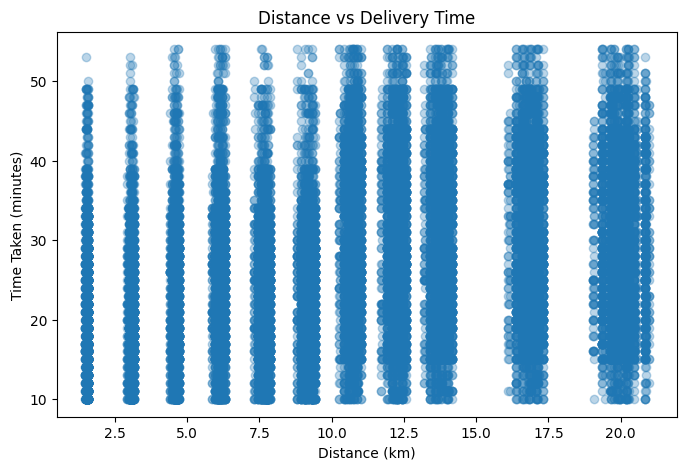

In [220]:
# رسم العلاقة بين المسافة ووقت التوصيل
plt.figure(figsize=(8, 5))
plt.scatter(
    valid_distance['distance_km'],
    valid_distance['Time_taken(min)'],
    alpha=0.3
)
plt.title('Distance vs Delivery Time')
plt.xlabel('Distance (km)')
plt.ylabel('Time Taken (minutes)')
plt.show()

### Preliminary Findings
### الاكتشافات الأولية

بعد تحليل البيانات ومقارنة بعض العوامل بوقت التوصيل، وصلت إلى الملاحظات التالية:

| العامل | النتيجة |
|---|---|
| Weather | الطقس الغائم والضبابي سجّل متوسط وقت أعلى بحوالي 29 دقيقة. |
| Traffic | الازدحام الشديد (Jam) سجّل أعلى متوسط بحوالي 31 دقيقة. |
| City | المدن Semi-Urban سجّلت متوسطًا يقارب 50 دقيقة، لكن عدد الطلبات فيها قليل. |
| Ratings | أغلب الطلبات كانت بتقييمات بين 4.5 و4.9. |
| Multiple Deliveries | زاد وقت التوصيل مع زيادة عدد التوصيلات، ووصل إلى حوالي 48 دقيقة عند وجود 3 توصيلات. |
| Distance | ظهرت علاقة موجبة بين المسافة ووقت التوصيل بقيمة 0.319، لكنها ليست قوية. |

### ملاحظات إضافية

- اكتشفت 431 سجلًا تحتوي على إحداثيات سالبة في أعمدة المطاعم، ونتج عنها مسافات غير منطقية.
- ظهرت قيم غير صحيحة أو مفقودة في بعض الأعمدة، وسيتم التعامل معها في مرحلة تنظيف البيانات.

هذه النتائج أولية، وقد تتغير بعد تنظيف البيانات وإعادة التحليل.

## Data Surprises | مفاجآت البيانات

أثناء تحليل البيانات لاحظت بعض المشاكل والقيم غير الطبيعية اللي تحتاج مراجعة قبل البدء بالتنظيف.

| المشكلة | الملاحظة | عدد السجلات |
|---|---|---:|
| Negative Coordinates | إحداثيات سالبة في أعمدة المطاعم أدت إلى حساب مسافات غير منطقية. | 431 |
| Missing Values | وجود قيم مفقودة في بعض الأعمدة. | يحتاج مراجعة |
| Invalid Values | وجود قيم غير طبيعية أو غير صحيحة في بعض الأعمدة. | يحتاج مراجعة |
| Data Types | وجود أعمدة تحتاج التأكد من نوع البيانات المخزن فيها. | يحتاج مراجعة |

هذه المشاكل تحتاج فحصًا إضافيًا لتحديد طريقة التعامل معها قبل اتخاذ قرارات التنظيف.

# 5. Data Cleaning + Decision Log

بعد الانتهاء من استكشاف البيانات وتحديد المشاكل الموجودة فيها، بدأت مرحلة التنظيف. راح أشتغل على نسخة من البيانات الأصلية عشان أقدر أراجع التغييرات وأقارن النتائج قبل وبعد التنظيف.

وبضيف جدول القرارات في البداية ثم اعدل عليه واحدثه كل ما اتخذ قرار جديد.

| Issue | Decision | Evidence / Reason | Affected Rows |
|---|---|---|---:|
| Zero restaurant coordinates | الاحتفاظ بالسجلات وتحويل `distance_km` إلى Missing | 3,640 سجل فيها إحداثيات المطاعم صفر، ومتوسط وقت التوصيل كان قريبًا من بقية البيانات | 3,640 |
| Negative restaurant coordinates | الاحتفاظ بالسجلات وتحويل `distance_km` إلى Missing | 431 سجل بإحداثيات مطاعم سالبة، وجميعها مسافتها أكبر من 100 كم | 431 |
| Unreliable distance | اعتبار المسافات الناتجة عن الإحداثيات غير الصحيحة Missing | المسافات المحسوبة من إحداثيات غير صحيحة لا يمكن الاعتماد عليها | 4,071 |
| Invalid delivery coordinates | الاحتفاظ بالسجلات وتحويل `distance_km` إلى Missing | 327 سجل تحتوي على إحداثيات توصيل بقيمة `0.01`، لذلك المسافة الناتجة عنها غير موثوقة | 327 |
| Missing ages stored as text | الاحتفاظ بالسجلات وتحويل القيم إلى Missing | 1,854 قيمة مفقودة (4.07%)، وحذف السجلات يعني فقدان بيانات الطلبات الأخرى | 1,854 |
| Missing and invalid ratings | الاحتفاظ بالسجلات وتحويل التقييمات المفقودة وغير الصحيحة إلى Missing | 1,908 تقييم مفقود و53 تقييم أعلى من الحد المسموح (5) | 1,961 |
| Missing multiple deliveries | الاحتفاظ بالسجلات وتحويل القيم المفقودة المكتوبة كنص إلى Missing | 993 قيمة مفقودة، وحذف الطلبات قد يؤدي إلى فقدان بقية المعلومات | 993 |

In [221]:
# إنشاء نسخة من البيانات الأصلية
df_clean = df.copy()

# التأكد من حجم البيانات
df_clean.shape

(45593, 21)

قبل البدء بالتنظيف، أنشأت نسخة من البيانات الأصلية عشان أقدر أطبق التعديلات عليها بدون ما تتأثر البيانات الأصلية، وأقدر أقارن النتائج قبل وبعد التنظيف.

In [222]:
# حساب القيم المفقودة في كل عمود
df_clean.isnull().sum().sort_values(ascending=False)

,0
distance_km,327
Delivery_person_ID,0
Delivery_person_Age,0
Delivery_person_Ratings,0
ID,0
Restaurant_latitude,0
Restaurant_longitude,0
Delivery_location_longitude,0
Delivery_location_latitude,0
Time_Orderd,0


لاحظت وجود 327 قيمة مفقودة

في عمود distance_km

 وهذه القيم ناتجة عن استبعاد المسافات المحسوبة باستخدام إحداثيات غير صحيحة، لذلك سأراجع هذه السجلات قبل اتخاذ قرار بشأنها.

In [223]:
# عرض السجلات التي لا تحتوي على مسافة محسوبة
df_clean.loc[
    df_clean['distance_km'].isna(),
    ['Restaurant_latitude', 'Restaurant_longitude',
     'Delivery_location_latitude', 'Delivery_location_longitude']
].head(10)

,Restaurant_latitude,Restaurant_longitude,Delivery_location_latitude,Delivery_location_longitude
153,0.0,0.0,0.01,0.01
359,0.0,0.0,0.01,0.01
468,0.0,0.0,0.01,0.01
610,0.0,0.0,0.01,0.01
643,0.0,0.0,0.01,0.01
663,0.0,0.0,0.01,0.01
672,0.0,0.0,0.01,0.01
1219,0.0,0.0,0.01,0.01
1802,0.0,0.0,0.01,0.01
1878,0.0,0.0,0.01,0.01


In [224]:
# فحص عدد السجلات التي تحتوي على إحداثيات صفرية
(df_clean['Restaurant_latitude'] == 0).sum()

np.int64(3640)

#### فحص الإحداثيات الصفرية

بعد ملاحظة وجود مسافات مفقودة، قررت أفحص أعمدة الإحداثيات الأربعة للتأكد من وجود قيم صفرية غير طبيعية في مواقع المطاعم والعملاء، ومعرفة مدى انتشار المشكلة قبل تحديد طريقة التعامل معها.

In [225]:
# فحص الإحداثيات الصفرية في أعمدة المطعم والعميل
print("Restaurant latitude = 0:",
      (df_clean['Restaurant_latitude'] == 0).sum())

print("Restaurant longitude = 0:",
      (df_clean['Restaurant_longitude'] == 0).sum())

print("Delivery latitude = 0:",
      (df_clean['Delivery_location_latitude'] == 0).sum())

print("Delivery longitude = 0:",
      (df_clean['Delivery_location_longitude'] == 0).sum())

Restaurant latitude = 0: 3640
Restaurant longitude = 0: 3640
Delivery latitude = 0: 0
Delivery longitude = 0: 0


لاحظت أن 3,640 سجلًا تحتوي على إحداثيات صفرية للمطاعم، بينما إحداثيات العملاء لا تحتوي على قيم صفرية.

ماقدر احذف كل السجلات قبل الفحص لذلك أحتاج إلى مراجعة الإحداثيات مع بعضها لتحديد السجلات التي تحتوي على مواقع غير صحيحة.

In [226]:
# فحص أنماط الإحداثيات الصفرية
df_clean.loc[
    (df_clean['Restaurant_latitude'] == 0) |
    (df_clean['Restaurant_longitude'] == 0),
    ['Restaurant_latitude', 'Restaurant_longitude',
     'Delivery_location_latitude', 'Delivery_location_longitude']
].head(15)

,Restaurant_latitude,Restaurant_longitude,Delivery_location_latitude,Delivery_location_longitude
33,0.0,0.0,0.11,0.11
52,0.0,0.0,0.03,0.03
57,0.0,0.0,0.08,0.08
59,0.0,0.0,0.06,0.06
67,0.0,0.0,0.02,0.02
68,0.0,0.0,0.04,0.04
72,0.0,0.0,0.08,0.08
73,0.0,0.0,0.02,0.02
76,0.0,0.0,0.05,0.05
81,0.0,0.0,0.11,0.11


In [227]:
# حساب أنماط الإحداثيات
print("Restaurant coordinates both zero:",
      ((df_clean['Restaurant_latitude'] == 0) &
       (df_clean['Restaurant_longitude'] == 0)).sum())

print("Delivery coordinates both zero:",
      ((df_clean['Delivery_location_latitude'] == 0) &
       (df_clean['Delivery_location_longitude'] == 0)).sum())

print("Both restaurant coordinates missing or zero:",
      ((df_clean['Restaurant_latitude'] == 0) |
       (df_clean['Restaurant_longitude'] == 0)).sum())

Restaurant coordinates both zero: 3640
Delivery coordinates both zero: 0
Both restaurant coordinates missing or zero: 3640


بعد التأكد من وجود 3,640 سجلًا بإحداثيات مطاعم صفرية، قررت الاحتفاظ بهذه السجلات لأن بقية بيانات الطلبات ما زالت مفيدة، مع عدم الاعتماد على المسافة المحسوبة منها. قبل تطبيق القرار، سأتحقق من عدد المسافات المتأثرة بهذه المشكلة.

In [228]:
# فحص المسافات للسجلات ذات إحداثيات المطاعم الصفرية
zero_restaurants = (
    (df_clean['Restaurant_latitude'] == 0) &
    (df_clean['Restaurant_longitude'] == 0)
)

print("Total affected rows:", zero_restaurants.sum())

print("Missing distances:",
      df_clean.loc[zero_restaurants, 'distance_km'].isna().sum())

print("Available distances:",
      df_clean.loc[zero_restaurants, 'distance_km'].notna().sum())

Total affected rows: 3640
Missing distances: 327
Available distances: 3313


In [229]:
# مقارنة المدن في السجلات ذات الإحداثيات الصفرية
df_clean.loc[zero_restaurants, 'City'].value_counts(dropna=False)

,count
City,
Metropolitian,2682
Urban,857
NaN,86
Semi-Urban,15


بعد مراجعة توزيع السجلات المتأثرة حسب المدينة، لاحظت أن المشكلة موجودة في أكثر من فئة. لذلك سأقارن متوسط وقت التوصيل بين السجلات ذات الإحداثيات الصفرية والسجلات الأخرى لمعرفة ما إذا كان هناك اختلاف واضح بينهما.

**Note**

أثناء مقارنة متوسط وقت التوصيل ظهر لي ايرورر وبعد مراجعته لاحظت أن عمود

`Time_taken(min)`

 ممكن يحتوي على أرقام مخزنة كنصوص، لذلك بفحص نوع البيانات قبل ما أكمل

In [230]:
# فحص نوع بيانات وقت التوصيل
print(df_clean['Time_taken(min)'].dtype)

# عرض عينة من القيم
print(df_clean['Time_taken(min)'].head(10))

object
0    (min) 24
1    (min) 33
2    (min) 26
3    (min) 21
4    (min) 30
5    (min) 26
6    (min) 40
7    (min) 32
8    (min) 34
9    (min) 46
Name: Time_taken(min), dtype: object


 سأزيل النص وأحوّل القيم إلى أرقام حتى أقدر أكمل التحليل.

In [231]:
# إزالة (min) وتحويل القيم إلى أرقام
df_clean['Time_taken(min)'] = (
    df_clean['Time_taken(min)']
    .str.replace('(min)', '', regex=False)
    .astype(int)
)

# التأكد من نوع البيانات
df_clean['Time_taken(min)'].dtype

dtype('int64')

In [232]:
# مقارنة متوسط وقت التوصيل
df_clean.groupby(zero_restaurants)['Time_taken(min)'].agg(
    ['count', 'mean', 'median']
)

,count,mean,median
False,41953,26.311539,26.0
True,3640,26.099451,25.0


**بعد المقارنه:**

قررت الاحتفاظ بالسجلات الـ3,640 بدل حذفها، لأن المشكلة موجودة في إحداثيات المطاعم فقط، بينما بقية معلومات الطلبات ما زالت متوفرة.

قارنت متوسط وقت التوصيل بين السجلات ذات الإحداثيات الصفرية والسجلات الأخرى، وكانت النتائج متقاربة (26.10 و26.31 دقيقة)، لذلك لم أجد سببًا واضحًا لحذف الطلبات كاملة.

لكن ما زلت غير متأكدة أن هذا أفضل قرار، لأن الاحتفاظ بهذه السجلات يعني فقدان معلومات المسافة لعدد كبير من الطلبات، وهذا قد يؤثر على التحليل والنموذج لاحقًا.

لذلك قررت الاحتفاظ بالطلبات حاليًا، مع اعتبار المسافات المرتبطة بالإحداثيات غير الصحيحة قيمًا مفقودة، وإعادة تقييم القرار إذا ظهرت مشكلة أثناء بناء النموذج.

In [233]:
zero_restaurants = (
    (df_clean['Restaurant_latitude'] == 0) &
    (df_clean['Restaurant_longitude'] == 0)
)

df_clean.loc[zero_restaurants, 'distance_km'] = np.nan

df_clean['distance_km'].isna().sum()

np.int64(3640)

In [234]:
df_clean.isnull().sum().sort_values(ascending=False)

,0
distance_km,3640
Delivery_person_ID,0
Delivery_person_Age,0
Delivery_person_Ratings,0
ID,0
Restaurant_latitude,0
Restaurant_longitude,0
Delivery_location_longitude,0
Delivery_location_latitude,0
Time_Orderd,0


In [235]:
# فحص القيم الغير طبيعية في الاعمدة الرقمية

df_clean.describe()

,Restaurant_latitude,Restaurant_longitude,Delivery_location_latitude,Delivery_location_longitude,Vehicle_condition,Time_taken(min),distance_km
count,45593.000000,45593.000000,45593.000000,45593.000000,45593.000000,45593.000000,41953.000000
mean,17.017729,70.231332,17.465186,70.845702,1.023359,26.294607,107.060101
std,8.185109,22.883647,7.335122,21.118812,0.839065,9.383806,1146.118637
min,-30.905562,-88.366217,0.010000,0.010000,0.000000,10.000000,1.465067
25%,12.933284,73.170000,12.988453,73.280000,0.000000,19.000000,4.658001
50%,18.546947,75.898497,18.633934,76.002574,1.000000,26.000000,9.220368
75%,22.728163,78.044095,22.785049,78.107044,2.000000,32.000000,13.760880
max,30.914057,88.433452,31.054057,88.563452,3.000000,54.000000,19692.674606


لاحظت وجود فرق كبير بين متوسط المسافة والوسيط، بالإضافة إلى وجود قيمة قصوى مرتفعة جدًا.

لذلك في الخطوة التالية سأفحص السجلات التي تحتوي على أكبر مسافات للتأكد من سبب ظهور هذه القيم.

In [236]:
df_clean.nlargest(10, 'distance_km')[
    ['Restaurant_latitude', 'Restaurant_longitude',
     'Delivery_location_latitude', 'Delivery_location_longitude',
     'distance_km'] ]

,Restaurant_latitude,Restaurant_longitude,Delivery_location_latitude,Delivery_location_longitude,distance_km
33533,-22.533662,-88.366217,22.663662,88.496217,19692.674606
6788,-22.552672,-88.352885,22.662672,88.462885,19688.001288
2484,-22.538999,-88.322337,22.668999,88.452337,19683.687561
18826,-22.537960,-88.349843,22.547960,88.359843,19677.180552
9535,-23.374989,-85.335486,23.444989,85.405486,19070.408110
762,-23.359194,-85.325447,23.449194,85.415447,19070.337839
35535,-23.369746,-85.339820,23.419746,85.389820,19069.158946
22291,-23.351058,-85.325731,23.421058,85.395731,19068.246962
30633,-23.357804,-85.325146,23.417804,85.385146,19067.128547
43454,-23.351058,-85.325731,23.401058,85.375731,19066.150742


- Restaurant_latitude سالبة.
- Delivery_location_latitude موجبة.
- قيم خطوط الطول متقاربة، لكن اختلاف اتجاه خطوط العرض يجعل المسافة المحسوبة تقارب 19 ألف كم
هذا يرجّح وجود خطأ في إحداثيات بعض السجلات، وليس مسافات توصيل حقيقية.

لكن قبل ما اقرر حذفها أو تعديلها، احتاج اعرف كم سجل متأثر بهذه المشكلة.

In [237]:
# تحديد عدد الاحداثيات السالبة

(df_clean['Restaurant_latitude'] < 0).sum()

np.int64(431)

In [238]:
(df_clean['Delivery_location_latitude'] < 0).sum()

np.int64(0)

In [239]:
# حساب عدد السجلات التي فيها إحداثيات مطعم سالبة، وكم منها مسافتها أكبر من 100 كم

negative_restaurants = df_clean['Restaurant_latitude'] < 0

(df_clean.loc[negative_restaurants, 'distance_km'] > 100).sum()

np.int64(431)

In [240]:
df_clean.loc[negative_restaurants, 'distance_km'].isnull().sum()

np.int64(0)

وجدت 431 سجلًا تحتوي على إحداثيات مطاعم سالبة، بينما لا توجد إحداثيات توصيل سالبة. وعند فحص المسافات، وجدت أن جميع السجلات الـ431 تتجاوز مسافتها 100 كم، مما يشير إلى أن الإحداثيات غير صحيحة. قررت الاحتفاظ بالطلبات نفسها وعدم حذفها، مع اعتبار المسافة فيها قيمة مفقودة، حتى لا أفقد بقية معلومات الطلبات.

In [241]:
# تحويل المسافات المرتبطة بإحداثيات المطاعم السالبة إلى قيم مفقودة لأنها غير موثوقة

negative_restaurants = df_clean['Restaurant_latitude'] < 0

df_clean.loc[negative_restaurants, 'distance_km'] = np.nan

df_clean['distance_km'].isna().sum()

np.int64(4071)

In [242]:
# التأكد من الأعمار
df_clean['Delivery_person_Age'].describe()

,Delivery_person_Age
count,45593
unique,23
top,35
freq,2262


In [243]:
# فحص الأعمار الموجودة للتأكد من عدم وجود قيم غير منطقية

df_clean['Delivery_person_Age'].unique()

array(['37', '34', '23', '38', '32', '22', '33', '35', '36', '21', '24',
       '29', '25', '31', '27', '26', '20', 'NaN ', '28', '39', '30', '15',
       '50'], dtype=object)

In [244]:
# حساب عدد القيم المفقودة المكتوبة كنص في عمود العمر

(df_clean['Delivery_person_Age'] == 'NaN ').sum()

np.int64(1854)

In [245]:
# حساب نسبة الأعمار المفقودة من إجمالي السجلات
(df_clean['Delivery_person_Age'] == 'NaN ').mean() * 100

np.float64(4.066413703858048)

In [246]:
# تحويل القيم المفقودة المكتوبة كنص إلى Missing Values فعلية
df_clean['Delivery_person_Age'] = df_clean['Delivery_person_Age'].replace('NaN ', np.nan)

df_clean['Delivery_person_Age'].isnull().sum()

np.int64(1854)

In [247]:
df_clean['Delivery_person_Age'].dtype

dtype('O')

In [248]:
# فحص قيم تقييم المندوب للتأكد من وجود قيم غير طبيعية أو مفقودة

df_clean['Delivery_person_Ratings'].unique()

array(['4.9', '4.5', '4.4', '4.7', '4.6', '4.8', '4.2', '4.3', '4', '4.1',
       '5', '3.5', 'NaN ', '3.8', '3.9', '3.7', '2.6', '2.5', '3.6',
       '3.1', '2.7', '1', '3.2', '3.3', '6', '3.4', '2.8', '2.9', '3'],
      dtype=object)

In [249]:
# حساب عدد التقييمات المفقودة والقيم التي تتجاوز الحد الأعلى للتقييم

ratings = pd.to_numeric(df_clean['Delivery_person_Ratings'], errors='coerce')

print("Missing ratings:", ratings.isnull().sum())
print("Ratings above 5:", (ratings > 5).sum())

Missing ratings: 1908
Ratings above 5: 53


In [250]:
# تحويل التقييمات غير الصحيحة أو المفقودة إلى Missing Values
df_clean['Delivery_person_Ratings'] = pd.to_numeric(
    df_clean['Delivery_person_Ratings'], errors='coerce'
)

df_clean.loc[df_clean['Delivery_person_Ratings'] > 5, 'Delivery_person_Ratings'] = np.nan

df_clean['Delivery_person_Ratings'].isnull().sum()

np.int64(1961)

In [251]:
# فحص عدد التوصيلات في الطلب للتأكد من القيم الموجودة والمفقودة
df_clean['multiple_deliveries'].unique()

array(['0', '1', '3', 'NaN ', '2'], dtype=object)

In [252]:
# حساب عدد القيم المفقودة المكتوبة كنص في عدد التوصيلات
(df_clean['multiple_deliveries'] == 'NaN ').sum()

np.int64(993)

In [253]:
# تحويل القيم المفقودة المكتوبة كنص إلى Missing Values
df_clean['multiple_deliveries'] = df_clean['multiple_deliveries'].replace('NaN ', np.nan)

df_clean['multiple_deliveries'].isnull().sum()

np.int64(993)

In [254]:
# التأكد من الاعمده بعد التنظيف
df_clean.isnull().sum()

,0
ID,0
Delivery_person_ID,0
Delivery_person_Age,1854
Delivery_person_Ratings,1961
Restaurant_latitude,0
Restaurant_longitude,0
Delivery_location_latitude,0
Delivery_location_longitude,0
Order_Date,0
Time_Orderd,0


In [255]:
df_clean.dtypes

,0
ID,object
Delivery_person_ID,object
Delivery_person_Age,object
Delivery_person_Ratings,float64
Restaurant_latitude,float64
Restaurant_longitude,float64
Delivery_location_latitude,float64
Delivery_location_longitude,float64
Order_Date,object
Time_Orderd,object


In [256]:
# تحويل العمر وعدد الطلبات إلى أرقام
df_clean['Delivery_person_Age'] = pd.to_numeric(
    df_clean['Delivery_person_Age'], errors='coerce'
)

df_clean['multiple_deliveries'] = pd.to_numeric(
    df_clean['multiple_deliveries'], errors='coerce'
)

df_clean[['Delivery_person_Age', 'multiple_deliveries']].dtypes

,0
Delivery_person_Age,float64
multiple_deliveries,float64


In [257]:
df_clean.shape

(45593, 21)

تم الانتهاء من تنظيف البيانات مع الاحتفاظ بجميع الصفوف.

تم التعامل مع القيم غير الصحيحة والمفقودة حسب القرارات الموضحة في

Decision Log

ولم يتم حذف أي صفوف من البيانات.

In [258]:
# حفظ البيانات بعد التنظيف
df_clean.to_csv('clean.csv', index=False)

# 6. Feature Engineering

في هذه المرحلة راح أضيف

Features

ممكن تساعد في توقع وقت التوصيل بناءً على المعلومات الموجودة في البيانات.

وبحاول أركز على عوامل ممكن يكون لها علاقة فعلية بوقت وصول الطلب.

**distance_km**

المسافة بين المطعم وموقع العميل ممكن تكون من العوامل المؤثرة في وقت التوصيل.

In [259]:
# عرض الاحصائيات
df_clean[['distance_km', 'Time_taken(min)']].describe()

,distance_km,Time_taken(min)
count,41522.000000,45593.000000
mean,9.720129,26.294607
std,5.603027,9.383806
min,1.465067,10.000000
25%,4.657655,19.000000
50%,9.193021,26.000000
75%,13.680920,32.000000
max,20.969489,54.000000


سوف أستخدم Scatter Plot

 لملاحظة العلاقة بين المسافة ووقت التوصيل، وهل زيادة المسافة ممكن ترتبط بزيادة الوقت.

In [260]:
import seaborn as sns
import matplotlib.pyplot as plt

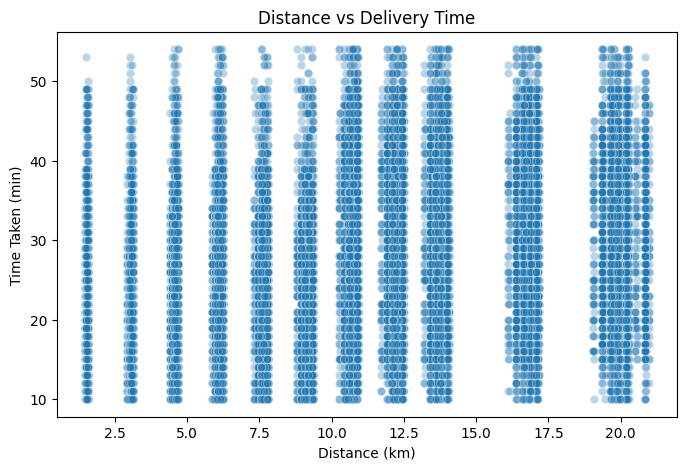

In [261]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df_clean,
    x='distance_km',
    y='Time_taken(min)',
    alpha=0.3
)

plt.title('Distance vs Delivery Time')
plt.xlabel('Distance (km)')
plt.ylabel('Time Taken (min)')
plt.show()

In [262]:
# تقسيم المسافات إلى مجموعات ومقارنة متوسط وقت التوصيل
df_clean.groupby(
    pd.cut(df_clean['distance_km'], bins=5)
)['Time_taken(min)'].mean()

/tmp/ipykernel_1385/41363340.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df_clean.groupby(


,Time_taken(min)
distance_km,
"(1.446, 5.366]",22.184857
"(5.366, 9.267]",24.478914
"(9.267, 13.168]",28.998270
"(13.168, 17.069]",29.872483
"(17.069, 20.969]",29.823095


نلاحظ أن متوسط وقت التوصيل يرتفع بشكل عام مع زيادة المسافة، حيث ارتفع من 22.18 دقيقة في أقصر مجموعة مسافات إلى حوالي 29.82 دقيقة في أطول مجموعة. وهذا يشير إلى أن المسافة ممكن تكون من العوامل المؤثرة في وقت التوصيل، لكنها ليست العامل الوحيد.

**Preparation Time**

وقت تجهيز الطلب ممكن يكون جزء من الوقت الكلي، لذلك راح أحسب الفرق بين وقت الطلب ووقت استلامه من السائق، وأشوف علاقته بوقت التوصيل.

In [263]:
# التحقق من شكل الوقت

df_clean[['Time_Orderd', 'Time_Order_picked']].head(10)

,Time_Orderd,Time_Order_picked
0,11:30:00,11:45:00
1,19:45:00,19:50:00
2,08:30:00,08:45:00
3,18:00:00,18:10:00
4,13:30:00,13:45:00
5,21:20:00,21:30:00
6,19:15:00,19:30:00
7,17:25:00,17:30:00
8,20:55:00,21:05:00
9,21:55:00,22:10:00


In [264]:
# تحويل الوقت إلى datetime
df_clean['Time_Orderd'] = pd.to_datetime(df_clean['Time_Orderd'], format='%H:%M:%S', errors='coerce')
df_clean['Time_Order_picked'] = pd.to_datetime(df_clean['Time_Order_picked'], format='%H:%M:%S', errors='coerce')

# حساب الفرق بالدقائق
df_clean['Preparation_Time'] = (df_clean['Time_Order_picked'] - df_clean['Time_Orderd']).dt.total_seconds() / 60

# تعديل الفرق إذا كان الوقت يتجاوز منتصف الليل
df_clean.loc[df_clean['Preparation_Time'] < 0, 'Preparation_Time'] += 1440

In [265]:
df_clean['Preparation_Time'].describe()

,Preparation_Time
count,43862.000000
mean,9.989399
std,4.087516
min,5.000000
25%,5.000000
50%,10.000000
75%,15.000000
max,15.000000


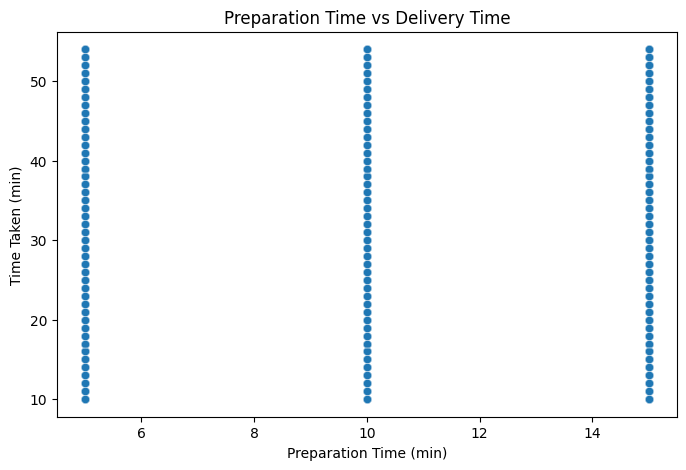

In [266]:
# scatterplot
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df_clean,
    x='Preparation_Time',
    y='Time_taken(min)',
    alpha=0.3
)

plt.title('Preparation Time vs Delivery Time')
plt.xlabel('Preparation Time (min)')
plt.ylabel('Time Taken (min)')
plt.show()

In [267]:
df_clean.groupby('Preparation_Time')['Time_taken(min)'].mean()

,Time_taken(min)
Preparation_Time,
5.0,26.352785
10.0,26.370541
15.0,26.158111


نلاحظ أن متوسط وقت التوصيل متقارب جدًا عند أوقات التجهيز المختلفة (5 و10 و15 دقيقة)، لذلك ما يظهر أن وقت التجهيز له تأثير واضح على وقت التوصيل في البيانات.

**Order Time**

وقت الطلب ممكن يكون له علاقة بوقت التوصيل، لذلك راح أستخرج الساعة من وقت الطلب وأشوف إذا تختلف مدة التوصيل حسب وقت اليوم.

In [268]:
df_clean['Order_Hour'] = df_clean['Time_Orderd'].dt.hour

In [269]:
# توزيع ساعات الطلب
df_clean['Order_Hour'].value_counts().sort_index()

,count
Order_Hour,
0.0,430
8.0,1818
9.0,1947
10.0,1991
11.0,1962
12.0,892
13.0,784
14.0,791
15.0,873


In [270]:
# متوسط وقت التوصيل لكل ساعة
df_clean.groupby('Order_Hour')['Time_taken(min)'].mean()

,Time_taken(min)
Order_Hour,
0.0,22.169767
8.0,19.584158
9.0,19.543914
10.0,19.482170
11.0,26.380734
12.0,26.826233
13.0,27.538265
14.0,27.537295
15.0,23.194731


نلاحظ اختلاف متوسط وقت التوصيل حسب ساعة الطلب، حيث كان أقل في ساعات الصباح (حوالي 19.5 دقيقة)، وارتفع في بعض ساعات الظهر، ووصل إلى أعلى متوسط تقريبًا بين الساعة 19 و21 (حوالي 31 دقيقة). وهذا يشير إلى أن وقت الطلب ممكن يكون له علاقة بمدة التوصيل.

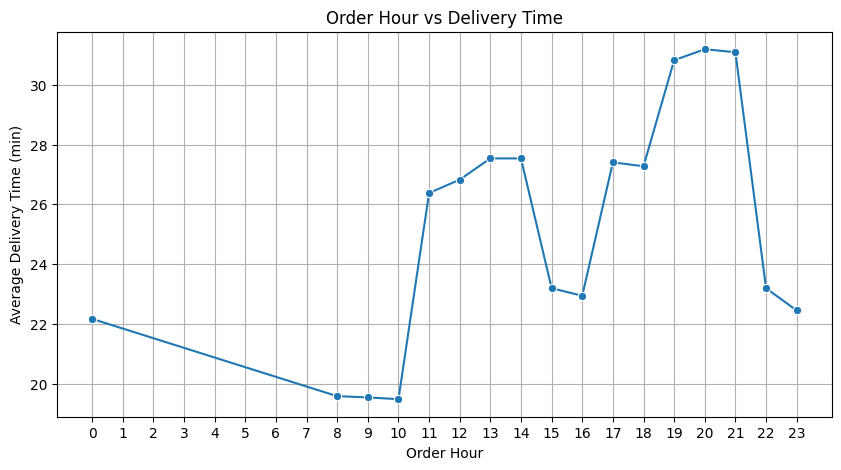

In [271]:
# حساب متوسط وقت التوصيل حسب ساعة الطلب لمعرفة إذا كان وقت الطلب يؤثر على مدة التوصيل

# Lineplot

plt.figure(figsize=(10, 5))

sns.lineplot(
    x=df_clean.groupby('Order_Hour')['Time_taken(min)'].mean().index,
    y=df_clean.groupby('Order_Hour')['Time_taken(min)'].mean().values,
    marker='o'
)

plt.title('Order Hour vs Delivery Time')
plt.xlabel('Order Hour')
plt.ylabel('Average Delivery Time (min)')
plt.xticks(range(0, 24))
plt.grid(True)
plt.show()

نلاحظ اختلاف وقت التوصيل حسب ساعة الطلب، حيث كان أقل في ساعات الصباح من 8 إلى 10، بينما ارتفع بشكل واضح في الفترة المسائية من 19 إلى 21. وهذا يشير إلى أن وقت الطلب قد يكون من العوامل المرتبطة بوقت التوصيل.

**بناءً على النتائج:**

قررت الاحتفاظ بـ
Order_Hour كـ Feature

 لأن النتائج أظهرت اختلافًا واضحًا في متوسط وقت التوصيل حسب ساعة الطلب.

 اصبح الان عندي 3 Features:

- distance_km
- Preparation_Time
- Order_Hour

# 7. Feature Selection

بعد ما انتهيت من
Feature Engineering

سيتم مراجعة الأعمدة

وتحديد أي Features

نحتاجها للتنبؤ بوقت التوصيل، وأي أعمدة ممكن استبعدها.

راح اعتمد على طبيعة العمود والنتائج اللي ظهرت خلال التحليل.

### جدول قرار مبدئي

### Feature Selection Decision Table

| Feature | Decision | Evidence / Reason |
|---|---|---|
| ID | Drop | رقم تعريفي للطلب ولا يمثل عاملًا مؤثرًا |
| Delivery_person_ID | Drop | رقم تعريفي للسائق ولا نريد أن يعتمد النموذج على هوية السائق |
| Delivery_person_Age | Keep | قد يكون له علاقة بطريقة التوصيل |
| Delivery_person_Ratings | Keep | تقييم السائق قد يكون مرتبطًا بأداء التوصيل |
| Restaurant_latitude | Drop | تم استخدام الإحداثيات في حساب المسافة |
| Restaurant_longitude | Drop | تم استخدام الإحداثيات في حساب المسافة |
| Delivery_location_latitude | Drop | تم استخدام الإحداثيات في حساب المسافة |
| Delivery_location_longitude | Drop | تم استخدام الإحداثيات في حساب المسافة |
| Order_Date | Review | نحتاج مراجعة إذا كان التاريخ يضيف معلومات مفيدة |
| Time_Orderd | Drop | تم استخراج Order_Hour منه |
| Time_Order_picked | Drop | تم استخراج Preparation_Time منه |
| Weatherconditions | Keep | حالة الطقس قد تؤثر على وقت التوصيل |
| Road_traffic_density | Keep | كثافة المرور قد تؤثر على وقت التوصيل |
| Vehicle_condition | Keep | حالة المركبة قد يكون لها علاقة بوقت التوصيل |
| Type_of_order | Keep | نوع الطلب قد يكون له علاقة بوقت التوصيل |
| Type_of_vehicle | Keep | نوع المركبة قد يؤثر على وقت التوصيل |
| multiple_deliveries | Keep | عدد الطلبات مع السائق قد يؤثر على وقت التوصيل |
| Festival | Keep | وجود مناسبة قد يؤثر على وقت التوصيل |
| City | Keep | المدينة قد يكون لها علاقة بوقت التوصيل |
| distance_km | Keep | أظهر التحليل ارتفاع وقت التوصيل مع زيادة المسافة |
| Preparation_Time | Review | متوسط وقت التوصيل كان متقاربًا بين أوقات التجهيز |
| Order_Hour | Keep | أظهر التحليل اختلافًا واضحًا في وقت التوصيل حسب ساعة الطلب |
| Time_taken(min) | Target | المتغير الذي نريد التنبؤ به |

In [272]:
# مراجعة الأعمدة الموجودة في البيانات
df_clean.columns

Index(['ID', 'Delivery_person_ID', 'Delivery_person_Age',
       'Delivery_person_Ratings', 'Restaurant_latitude',
       'Restaurant_longitude', 'Delivery_location_latitude',
       'Delivery_location_longitude', 'Order_Date', 'Time_Orderd',
       'Time_Order_picked', 'Weatherconditions', 'Road_traffic_density',
       'Vehicle_condition', 'Type_of_order', 'Type_of_vehicle',
       'multiple_deliveries', 'Festival', 'City', 'Time_taken(min)',
       'distance_km', 'Preparation_Time', 'Order_Hour'],
      dtype='object')

In [273]:
# مراجعة عدد الطلبات حسب التاريخ
df_clean['Order_Date'].value_counts().sort_index()

,count
Order_Date,
01-03-2022,1140
01-04-2022,1133
02-03-2022,1012
02-04-2022,992
03-03-2022,1150
03-04-2022,1178
04-03-2022,981
04-04-2022,941
05-03-2022,1154


In [274]:
# متوسط وقت التوصيل حسب التاريخ
df_clean.groupby('Order_Date')['Time_taken(min)'].mean().sort_index()

,Time_taken(min)
Order_Date,
01-03-2022,23.226316
01-04-2022,23.369815
02-03-2022,29.507905
02-04-2022,29.718750
03-03-2022,23.054783
03-04-2022,23.074703
04-03-2022,29.577982
04-04-2022,29.381509
05-03-2022,23.080589


### جدول قرار بعد المراجعة

### Final Feature Selection Decision Table

| Feature | Decision | Evidence / Reason |
|---|---|---|
| ID | Drop | رقم تعريفي للطلب ولا يمثل عاملًا مؤثرًا |
| Delivery_person_ID | Drop | رقم تعريفي للسائق ولا نريد أن يعتمد النموذج على هوية السائق |
| Delivery_person_Age | Keep | قد يكون له علاقة بطريقة التوصيل |
| Delivery_person_Ratings | Keep | تقييم السائق قد يكون مرتبطًا بأداء التوصيل |
| Restaurant_latitude | Drop | تم استخدام الإحداثيات في حساب المسافة |
| Restaurant_longitude | Drop | تم استخدام الإحداثيات في حساب المسافة |
| Delivery_location_latitude | Drop | تم استخدام الإحداثيات في حساب المسافة |
| Delivery_location_longitude | Drop | تم استخدام الإحداثيات في حساب المسافة |
| Order_Date | Drop | لم يتم الاحتفاظ بالتاريخ لأننا نركز على العوامل المرتبطة بوقت التوصيل، وليس التاريخ نفسه |
| Time_Orderd | Drop | تم استخراج Order_Hour منه |
| Time_Order_picked | Drop | تم استخدامه مع وقت الطلب لحساب Preparation_Time |
| Weatherconditions | Keep | حالة الطقس قد تؤثر على وقت التوصيل |
| Road_traffic_density | Keep | كثافة المرور قد تؤثر على وقت التوصيل |
| Vehicle_condition | Keep | حالة المركبة قد يكون لها علاقة بوقت التوصيل |
| Type_of_order | Keep | نوع الطلب قد يكون له علاقة بوقت التوصيل |
| Type_of_vehicle | Keep | نوع المركبة قد يؤثر على وقت التوصيل |
| multiple_deliveries | Keep | عدد الطلبات مع السائق قد يؤثر على وقت التوصيل |
| Festival | Keep | وجود مناسبة قد يؤثر على وقت التوصيل |
| City | Keep | المدينة قد يكون لها علاقة بوقت التوصيل |
| distance_km | Keep | أظهر التحليل ارتفاع وقت التوصيل مع زيادة المسافة |
| Preparation_Time | Drop | متوسط وقت التوصيل كان متقاربًا بين أوقات التجهيز المختلفة، ولم يظهر تأثير واضح |
| Order_Hour | Keep | أظهر التحليل اختلافًا واضحًا في وقت التوصيل حسب ساعة الطلب |
| Time_taken(min) | Target | المتغير الذي نريد التنبؤ به |

In [275]:
# عرض الأعمدة الموجودة حاليًا
df_clean.columns.tolist()

['ID',
 'Delivery_person_ID',
 'Delivery_person_Age',
 'Delivery_person_Ratings',
 'Restaurant_latitude',
 'Restaurant_longitude',
 'Delivery_location_latitude',
 'Delivery_location_longitude',
 'Order_Date',
 'Time_Orderd',
 'Time_Order_picked',
 'Weatherconditions',
 'Road_traffic_density',
 'Vehicle_condition',
 'Type_of_order',
 'Type_of_vehicle',
 'multiple_deliveries',
 'Festival',
 'City',
 'Time_taken(min)',
 'distance_km',
 'Preparation_Time',
 'Order_Hour']

In [276]:
# حذف الأعمدة التي قررت استبعادها
drop_columns = [
    'ID',
    'Delivery_person_ID',
    'Restaurant_latitude',
    'Restaurant_longitude',
    'Delivery_location_latitude',
    'Delivery_location_longitude',
    'Order_Date',
    'Time_Orderd',
    'Time_Order_picked',
    'Preparation_Time'
]

df_model = df_clean.drop(columns=drop_columns)

# عرض الأعمدة المتبقية
df_model.columns.tolist()

['Delivery_person_Age',
 'Delivery_person_Ratings',
 'Weatherconditions',
 'Road_traffic_density',
 'Vehicle_condition',
 'Type_of_order',
 'Type_of_vehicle',
 'multiple_deliveries',
 'Festival',
 'City',
 'Time_taken(min)',
 'distance_km',
 'Order_Hour']

In [277]:
# فحص شكل البيانات والقيم المفقودة بعد Feature Selection
print("Shape:", df_model.shape)
print("\nMissing values:")
print(df_model.isnull().sum())

Shape: (45593, 13)

Missing values:
Delivery_person_Age        1854
Delivery_person_Ratings    1961
Weatherconditions             0
Road_traffic_density          0
Vehicle_condition             0
Type_of_order                 0
Type_of_vehicle               0
multiple_deliveries         993
Festival                      0
City                          0
Time_taken(min)               0
distance_km                4071
Order_Hour                 1731
dtype: int64


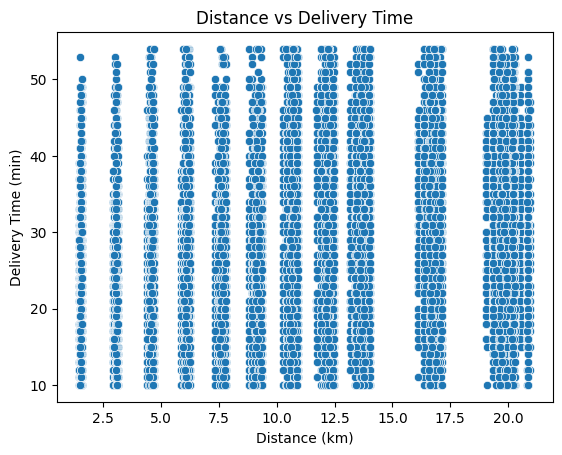

In [278]:
# الرسم لدعم قرارت feature selection

import seaborn as sns
import matplotlib.pyplot as plt

# العلاقة بين المسافة ووقت التوصيل
sns.scatterplot(data=df_model, x='distance_km', y='Time_taken(min)')

plt.title('Distance vs Delivery Time')
plt.xlabel('Distance (km)')
plt.ylabel('Delivery Time (min)')
plt.show()

يوضح الرسم توزيع وقت التوصيل حسب المسافة، ونلاحظ وجود اختلاف في أوقات التوصيل عند المسافات المختلفة.

وبشكل عام، أظهر التحليل السابق ارتفاع متوسط وقت التوصيل مع زيادة المسافة،

لذلك قررت الاحتفاظ بـ `distance_km`

كـ  Feature.

In [279]:
# إنشاء مجلد data
import os

os.makedirs('data', exist_ok=True)

# حفظ البيانات بعد Feature Selection
df_model.to_csv('data/model_ready.csv', index=False)

print("File saved successfully!")
print("Final Shape:", df_model.shape)

File saved successfully!
Final Shape: (45593, 13)


In [280]:
import os

# عرض الملفات الموجودة داخل مجلد data
os.listdir('data')

['model_ready.csv', 'clean.csv']

In [281]:
# حفظ البيانات النظيفة داخل مجلد data
df_clean.to_csv('data/clean.csv', index=False)

print("clean.csv saved successfully!")

clean.csv saved successfully!


In [282]:
os.listdir('data')

['model_ready.csv', 'clean.csv']

# 8. الأكتشافات

### Discovery 1: تأثير كثافة المرور على وقت التوصيل

لاحظنا اختلافًا في متوسط وقت التوصيل حسب كثافة المرور، لذلك سنقارن متوسط وقت التوصيل بين مستويات المرور المختلفة لمعرفة مدى تأثيرها المحتمل على وقت التوصيل.

In [283]:
# متوسط وقت التوصيل حسب كثافة المرور
traffic_avg = df_clean.groupby('Road_traffic_density')['Time_taken(min)'].mean().sort_values()

traffic_avg

,Time_taken(min)
Road_traffic_density,
Low,21.266977
NaN,26.542429
Medium,26.699644
High,27.240000
Jam,31.176624


In [284]:
# فحص متوسطات المرور قبل الرسم
print(traffic_avg)

print("\nValues:")
print(traffic_avg.values)

print("\nIndex:")
print(traffic_avg.index.tolist())

Road_traffic_density
Low        21.266977
NaN        26.542429
Medium     26.699644
High       27.240000
Jam        31.176624
Name: Time_taken(min), dtype: float64

Values:
[21.2669768  26.54242928 26.69964374 27.24       31.17662448]

Index:
['Low ', 'NaN ', 'Medium ', 'High ', 'Jam ']


In [285]:
# حساب متوسط وقت التوصيل حسب كثافة المرور من جديد
traffic_avg = df_clean.groupby('Road_traffic_density')['Time_taken(min)'].mean()

print(traffic_avg)

Road_traffic_density
High       27.240000
Jam        31.176624
Low        21.266977
Medium     26.699644
NaN        26.542429
Name: Time_taken(min), dtype: float64


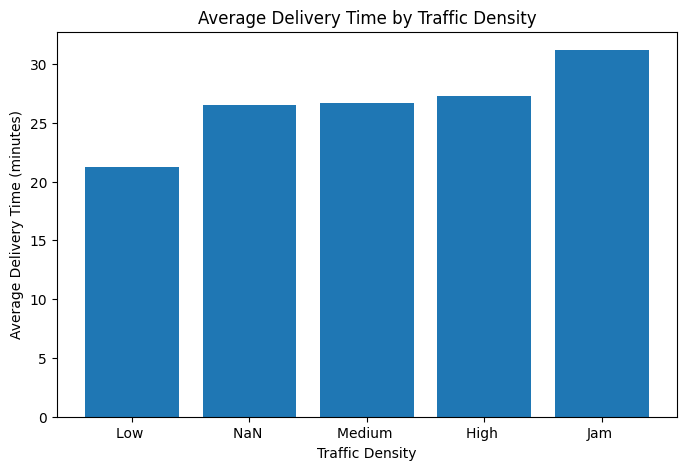

In [286]:
# حساب متوسط وقت التوصيل حسب كثافة المرور
traffic_avg = df_clean.groupby('Road_traffic_density')['Time_taken(min)'].mean()

# حذف القيم المفقودة
traffic_avg = traffic_avg.dropna()

# ترتيب قيم المرور
traffic_avg = traffic_avg.sort_values()

# رسم النتائج
plt.figure(figsize=(8, 5))
plt.bar(traffic_avg.index, traffic_avg.values)

plt.title('Average Delivery Time by Traffic Density')
plt.xlabel('Traffic Density')
plt.ylabel('Average Delivery Time (minutes)')
plt.show()

لاحظت أن متوسط وقت التوصيل يختلف حسب كثافة المرور، حيث كان أقل وقت عند المرور المنخفض بمتوسط 21.27 دقيقة، بينما ارتفع إلى 31.18 دقيقة عند وجود ازدحام (Jam). أما البيانات التي كانت فيها كثافة المرور مفقودة، فكان متوسط وقت التوصيل فيها 26.54 دقيقة. وهذا يشير إلى أن ازدحام الطرق قد يكون مرتبطًا بزيادة وقت التوصيل.

### Discovery 2: تأثير عدد الطلبات على وقت التوصيل

In [287]:
# حساب متوسط وقت التوصيل حسب عدد الطلبات
delivery_avg = df_clean.groupby('multiple_deliveries')['Time_taken(min)'].mean()

delivery_avg

,Time_taken(min)
multiple_deliveries,
0.0,22.876268
1.0,26.855890
2.0,40.454912
3.0,47.819945


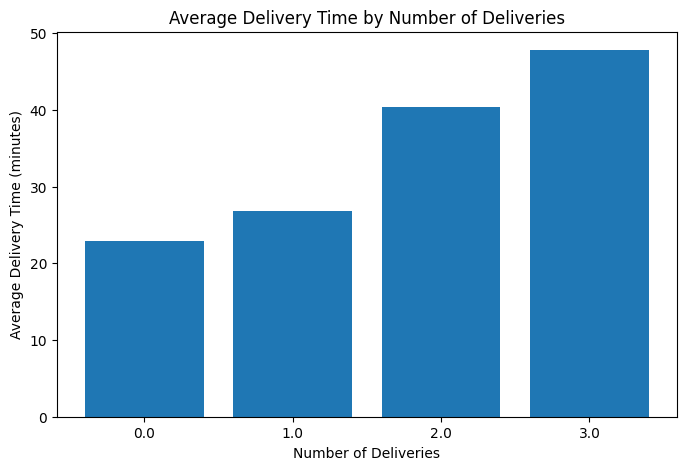

In [288]:
# رسم متوسط وقت التوصيل حسب عدد الطلبات
plt.figure(figsize=(8, 5))
plt.bar(delivery_avg.index.astype(str), delivery_avg.values)

plt.title('Average Delivery Time by Number of Deliveries')
plt.xlabel('Number of Deliveries')
plt.ylabel('Average Delivery Time (minutes)')
plt.show()

من النتائج واضح أن زيادة عدد الطلبات مع المندوب ترفع وقت التوصيل، والفرق صار أكبر لما وصل عدد الطلبات إلى 2 و3، لذلك عدد الطلبات يعتبر من العوامل المهمة اللي نحتاج ننتبه لها.

# Discovery 3: تأثير الطقس على وقت التوصيل

In [289]:
# حساب متوسط وقت التوصيل حسب حالة الطقس
weather_avg = df_clean.groupby('Weatherconditions')['Time_taken(min)'].mean().sort_values()

weather_avg

,Time_taken(min)
Weatherconditions,
conditions Sunny,21.856947
conditions Stormy,25.870815
conditions Sandstorms,25.875517
conditions Windy,26.118836
conditions NaN,26.545455
conditions Fog,28.916122
conditions Cloudy,28.917330


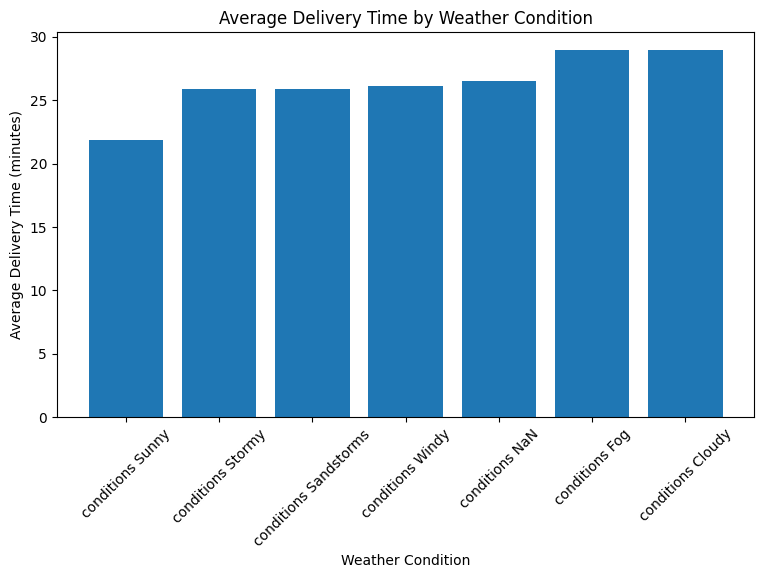

In [290]:
# رسم متوسط وقت التوصيل حسب حالة الطقس
plt.figure(figsize=(9, 5))
plt.bar(weather_avg.index, weather_avg.values)

plt.title('Average Delivery Time by Weather Condition')
plt.xlabel('Weather Condition')
plt.ylabel('Average Delivery Time (minutes)')
plt.xticks(rotation=45)
plt.show()

نلاحظ أن وقت التوصيل كان أقل في
Sunny

 بمتوسط حوالي 21.86 دقيقة،

بينما كان أعلى في
Cloudy وFog

بحوالي 28.9 دقيقة.

الفرق بين الحالات يعطينا مؤشر أن الطقس ممكن يكون له تأثير على وقت التوصيل، لكن نحتاج ننتبه لأن بعض الحالات متوسطاتها متقاربة.

# Discovry 4: وقت الطلب خلال اليوم

In [291]:
# حساب متوسط وقت التوصيل حسب ساعة الطلب
hour_avg = df_clean.groupby('Order_Hour')['Time_taken(min)'].mean()

hour_avg

,Time_taken(min)
Order_Hour,
0.0,22.169767
8.0,19.584158
9.0,19.543914
10.0,19.482170
11.0,26.380734
12.0,26.826233
13.0,27.538265
14.0,27.537295
15.0,23.194731


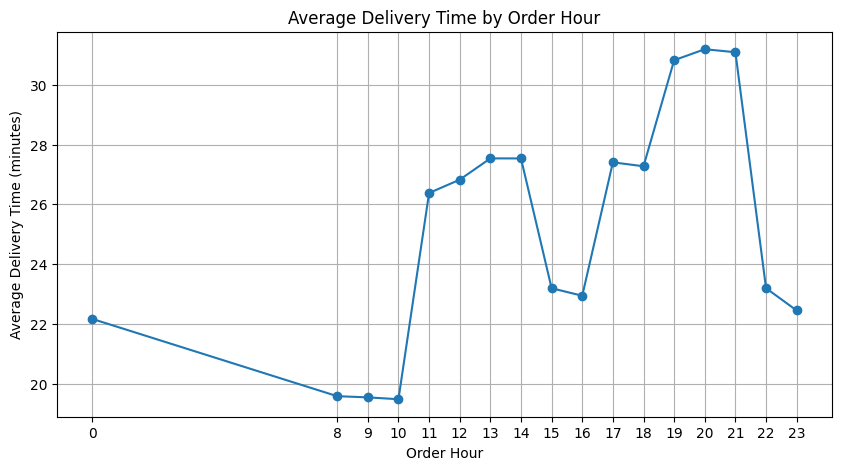

In [292]:
# رسم متوسط وقت التوصيل حسب ساعة الطلب
plt.figure(figsize=(10, 5))
plt.plot(hour_avg.index, hour_avg.values, marker='o')

plt.title('Average Delivery Time by Order Hour')
plt.xlabel('Order Hour')
plt.ylabel('Average Delivery Time (minutes)')
plt.xticks(hour_avg.index)
plt.grid()
plt.show()

نلاحظ أن وقت التوصيل كان أقل خلال ساعات الصباح من 8 إلى 10، بمتوسط حوالي 19.5 دقيقة، بينما ارتفع بشكل واضح في المساء، خصوصًا من الساعة 19 إلى 21، ووصل المتوسط إلى أكثر من 31 دقيقة.

وهذا يوضح أن وقت الطلب خلال اليوم ممكن يكون له علاقة بوقت التوصيل.

### Discovery 5: المسافة وتأثيرها على وقت التوصيل

In [293]:
# تقسيم المسافات إلى مجموعات
df_clean['Distance_Category'] = pd.cut(
    df_clean['distance_km'],
    bins=5
)

# حساب متوسط وقت التوصيل لكل مجموعة
distance_avg = df_clean.groupby('Distance_Category', observed=True)['Time_taken(min)'].mean()

distance_avg

,Time_taken(min)
Distance_Category,
"(1.446, 5.366]",22.184857
"(5.366, 9.267]",24.478914
"(9.267, 13.168]",28.998270
"(13.168, 17.069]",29.872483
"(17.069, 20.969]",29.823095


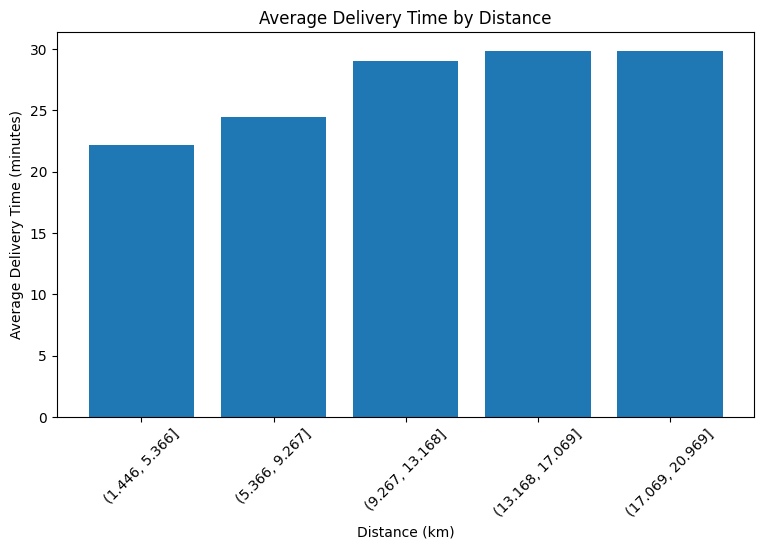

In [294]:
# رسم متوسط وقت التوصيل حسب المسافة
plt.figure(figsize=(9, 5))
plt.bar(distance_avg.index.astype(str), distance_avg.values)

plt.title('Average Delivery Time by Distance')
plt.xlabel('Distance (km)')
plt.ylabel('Average Delivery Time (minutes)')
plt.xticks(rotation=45)
plt.show()

نلاحظ أن متوسط وقت التوصيل يزيد مع زيادة المسافة، حيث كان حوالي 22.18 دقيقة للمسافات القصيرة، وارتفع إلى حوالي 29.87 دقيقة للمسافات الأطول. لكن الزيادة أصبحت بسيطة في آخر مجموعتين، وهذا يدل أن المسافة مرتبطة بوقت التوصيل، لكن فيه عوامل أخرى ممكن تأثر أيضًا.

### 9. التوصيات

بناءً على النتائج اللي ظهرت لنا من تحليل البيانات، سوف اقترح بعض الإجراءات اللتي ممكن تساعد في تحسين وقت التوصيل:

1. تنظيم الطلبات المجمّعة:

مراجعة عدد الطلبات اللي يتم إسنادها للمندوب في نفس الوقت، لأن النتائج أظهرت ارتفاعًا واضحًا في وقت التوصيل عند زيادة عدد الطلبات، خصوصًا عند وجود طلبين أو ثلاثة.

2. مراعاة كثافة المرور:

محاولة توزيع الطلبات أو تحديد وقت التوصيل المتوقع بناءً على حالة المرور، لأن متوسط وقت التوصيل ارتفع من حوالي 21.27 دقيقة في المرور المنخفض إلى 31.18 دقيقة في حالة الازدحام.

3. تحسين تقدير وقت التوصيل حسب المسافة ووقت الطلب:

أخذ المسافة وساعة الطلب في الاعتبار عند تقدير وقت التوصيل، لأن النتائج أظهرت أن الطلبات الأطول مسافة وطلبات المساء تستغرق وقتًا أكبر بشكل عام.


**What the Data Cannot Tell Us:**

النتائج توضح وجود علاقة بين بعض العوامل ووقت التوصيل، لكن ما نقدر نأكد أن هذه العوامل هي السبب المباشر في زيادة الوقت، لأن ممكن توجد عوامل أخرى لم يتم تحليلها في البيانات.

# 10. DashBorad النسخة الأولى

In [295]:
# تثبيت streamlit

!pip install streamlit

In [296]:
# انشاء ملف app.py

%%writefile app.py

import streamlit as st
import pandas as pd

# تحميل البيانات
df = pd.read_csv('clean.csv')

st.title("Delivery Time Dashboard")
st.write("Dashboard to explore delivery time and the factors affecting it.")

Overwriting app.py


### إنشاء الفلاتر

في هذه الخطوة راح نضيف فلاتر تفاعلية للمستخدم، بحيث يقدر يختار المدينة، والطقس، وكثافة المرور، وعدد الطلبات مع المندوب.

وبعدها تتغير البيانات المعروضة في
Dashboard حسب الاختيارات.

In [297]:
%%writefile app.py

import streamlit as st
import pandas as pd

# تحميل البيانات
df = pd.read_csv('clean.csv')

st.title("Delivery Time Dashboard")
st.write("Dashboard to explore delivery time and the factors affecting it.")

# Filters
st.sidebar.header("Filters")

city_options = ['All'] + list(df['City'].dropna().unique())
selected_city = st.sidebar.selectbox("City", city_options)

weather_options = ['All'] + list(df['Weatherconditions'].dropna().unique())
selected_weather = st.sidebar.selectbox("Weather", weather_options)

traffic_options = ['All'] + list(df['Road_traffic_density'].dropna().unique())
selected_traffic = st.sidebar.selectbox("Road Traffic", traffic_options)

delivery_options = ['All'] + list(df['multiple_deliveries'].dropna().unique())
selected_delivery = st.sidebar.selectbox("Multiple Deliveries", delivery_options)

# Apply filters
filtered_df = df.copy()

if selected_city != 'All':
    filtered_df = filtered_df[filtered_df['City'] == selected_city]

if selected_weather != 'All':
    filtered_df = filtered_df[filtered_df['Weatherconditions'] == selected_weather]

if selected_traffic != 'All':
    filtered_df = filtered_df[filtered_df['Road_traffic_density'] == selected_traffic]

if selected_delivery != 'All':
    filtered_df = filtered_df[filtered_df['multiple_deliveries'] == selected_delivery]

Overwriting app.py


### عرض المؤشرات الرئيسية

في هذا الجزء سوف اعرض معلومات مختصرة عن الطلبات، مثل متوسط وقت التوصيل، عدد الطلبات، متوسط المسافة، ومتوسط تقييم المندوب.

المؤشرات سوف تتغير حسب الفلاتر اللي يختارها المستخدم.

In [298]:
%%writefile app.py

import streamlit as st
import pandas as pd

# تحميل البيانات
df = pd.read_csv('clean.csv')

st.title("Delivery Time Dashboard")
st.write("Dashboard to explore delivery time and the factors affecting it.")

# Filters
st.sidebar.header("Filters")

city_options = ['All'] + list(df['City'].dropna().unique())
selected_city = st.sidebar.selectbox("City", city_options)

weather_options = ['All'] + list(df['Weatherconditions'].dropna().unique())
selected_weather = st.sidebar.selectbox("Weather", weather_options)

traffic_options = ['All'] + list(df['Road_traffic_density'].dropna().unique())
selected_traffic = st.sidebar.selectbox("Road Traffic", traffic_options)

delivery_options = ['All'] + list(df['multiple_deliveries'].dropna().unique())
selected_delivery = st.sidebar.selectbox("Multiple Deliveries", delivery_options)

# Apply filters
filtered_df = df.copy()

if selected_city != 'All':
    filtered_df = filtered_df[filtered_df['City'] == selected_city]

if selected_weather != 'All':
    filtered_df = filtered_df[filtered_df['Weatherconditions'] == selected_weather]

if selected_traffic != 'All':
    filtered_df = filtered_df[filtered_df['Road_traffic_density'] == selected_traffic]

if selected_delivery != 'All':
    filtered_df = filtered_df[filtered_df['multiple_deliveries'] == selected_delivery]

# Metrics
st.header("Key Metrics")

col1, col2, col3, col4 = st.columns(4)

col1.metric("Average Delivery Time", round(filtered_df['Time_taken(min)'].mean(), 2))
col2.metric("Total Orders", len(filtered_df))
col3.metric("Average Distance (km)", round(filtered_df['distance_km'].mean(), 2))
col4.metric("Average Rating", round(filtered_df['Delivery_person_Ratings'].mean(), 2))

Overwriting app.py


### عرض الرسوم البيانية

في هذا الجزء سوف اعرض أهم النتائج اللي توصلت لها في التحليل، باستخدام رسوم بيانية تساعد على فهم العلاقة بين وقت التوصيل وبعض العوامل، مثل كثافة المرور، وعدد الطلبات مع المندوب، وساعة الطلب.

والرسوم راح تتغير حسب الفلاتر اللي يختارها المستخدم.

In [299]:
%%writefile app.py

import streamlit as st
import pandas as pd

# تحميل البيانات
df = pd.read_csv('clean.csv')

st.title("Delivery Time Dashboard")
st.write("Dashboard to explore delivery time and the factors affecting it.")

# Filters
st.sidebar.header("Filters")

city_options = ['All'] + list(df['City'].dropna().unique())
selected_city = st.sidebar.selectbox("City", city_options)

weather_options = ['All'] + list(df['Weatherconditions'].dropna().unique())
selected_weather = st.sidebar.selectbox("Weather", weather_options)

traffic_options = ['All'] + list(df['Road_traffic_density'].dropna().unique())
selected_traffic = st.sidebar.selectbox("Road Traffic", traffic_options)

delivery_options = ['All'] + list(df['multiple_deliveries'].dropna().unique())
selected_delivery = st.sidebar.selectbox("Multiple Deliveries", delivery_options)

# Apply filters
filtered_df = df.copy()

if selected_city != 'All':
    filtered_df = filtered_df[filtered_df['City'] == selected_city]

if selected_weather != 'All':
    filtered_df = filtered_df[filtered_df['Weatherconditions'] == selected_weather]

if selected_traffic != 'All':
    filtered_df = filtered_df[filtered_df['Road_traffic_density'] == selected_traffic]

if selected_delivery != 'All':
    filtered_df = filtered_df[filtered_df['multiple_deliveries'] == selected_delivery]

# Metrics
st.header("Key Metrics")

col1, col2, col3, col4 = st.columns(4)

col1.metric("Average Delivery Time", round(filtered_df['Time_taken(min)'].mean(), 2))
col2.metric("Total Orders", len(filtered_df))
col3.metric("Average Distance (km)", round(filtered_df['distance_km'].mean(), 2))
col4.metric("Average Rating", round(filtered_df['Delivery_person_Ratings'].mean(), 2))

# Charts
st.header("Delivery Insights")

# Chart 1: Traffic
traffic_avg = filtered_df.groupby('Road_traffic_density')['Time_taken(min)'].mean()

st.subheader("Average Delivery Time by Road Traffic")
st.bar_chart(traffic_avg)

# Chart 2: Multiple Deliveries
delivery_avg = filtered_df.groupby('multiple_deliveries')['Time_taken(min)'].mean()

st.subheader("Average Delivery Time by Multiple Deliveries")
st.bar_chart(delivery_avg)

# Chart 3: Order Hour
filtered_df['Order_Hour'] = pd.to_datetime(
    filtered_df['Time_Orderd'], format='%H:%M', errors='coerce'
).dt.hour

hour_avg = filtered_df.groupby('Order_Hour')['Time_taken(min)'].mean()

st.subheader("Average Delivery Time by Hour")
st.line_chart(hour_avg)

Overwriting app.py


In [300]:
# تشغيل streamlit

!streamlit run app.py &>/content/log.txt &

In [301]:
!pip install pyngrok

In [302]:
!cat /content/log.txt



2026-11-26 05:51:22.291 Uvicorn server started on :::8502

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8502
  Network URL: http://172.28.0.12:8502
  External URL: http://136.66.55.237:8502



In [306]:
from google.colab import userdata
from pyngrok import ngrok

ngrok.set_auth_token(userdata.get('NGROK_AUTH_TOKEN'))

public_url = ngrok.connect(8502)
print(public_url)

PyngrokNgrokError: An error occurred when saving the auth token: b'Authtoken already set in configuration file: /root/.config/ngrok/ngrok.yml\n'

### ملاحظات على النسخة الأولية

بعد تشغيل الـ Dashboard وتجربته، لاحظت أن الفلاتر والـ Metrics والرسوم البيانية تعمل بشكل عام، لكن ظهرت بعض الملاحظات أثناء التجربة:

- بعض القيم الناقصة تظهر في خيارات الفلاتر على شكل `NaN`.
- الفلاتر تسمح باختيار قيمة واحدة فقط، وليس أكثر من قيمة في نفس الوقت.
- عند اختيار فلاتر متعددة، قد لا توجد بيانات تطابق جميع الاختيارات، مما يؤدي إلى ظهور قيم فارغة في الـ Metrics.
- لاحظت أن بعض الرسوم لا تتأثر بالفلاتر بالشكل المتوقع، لذلك تحتاج إلى مراجعة.

كانت هذه التجربة مفيدة في اكتشاف بعض النقاط التي يمكن تحسينها، وأعتبر النسخة الحالية نموذجًا أوليًا سيتم تطويره لاحقًا.

# 11. DashBorad شامل

In [307]:
%%writefile app.py

import streamlit as st
import pandas as pd

# تحميل البيانات
df = pd.read_csv('clean.csv')

st.title("Delivery Time Dashboard")
st.write("Dashboard to explore delivery time and the factors affecting it.")


# Filters
st.sidebar.header("Filters")

# التعامل مع القيم الناقصة
df['City'] = df['City'].fillna('Unknown')
df['Weatherconditions'] = df['Weatherconditions'].fillna('Unknown')
df['Road_traffic_density'] = df['Road_traffic_density'].fillna('Unknown')
df['multiple_deliveries'] = df['multiple_deliveries'].fillna('Unknown')


# City Filter
city_options = ['All'] + list(df['City'].unique())
selected_city = st.sidebar.selectbox("City", city_options)

# Weather Filter
weather_options = ['All'] + list(df['Weatherconditions'].unique())
selected_weather = st.sidebar.selectbox("Weather", weather_options)

# Road Traffic Filter
traffic_options = ['All'] + list(df['Road_traffic_density'].unique())
selected_traffic = st.sidebar.selectbox("Road Traffic", traffic_options)

# Multiple Deliveries Filter
delivery_options = ['All'] + list(df['multiple_deliveries'].unique())
selected_delivery = st.sidebar.selectbox("Multiple Deliveries", delivery_options)


# Apply filters
filtered_df = df.copy()

if selected_city != 'All':
    filtered_df = filtered_df[filtered_df['City'] == selected_city]

if selected_weather != 'All':
    filtered_df = filtered_df[filtered_df['Weatherconditions'] == selected_weather]

if selected_traffic != 'All':
    filtered_df = filtered_df[filtered_df['Road_traffic_density'] == selected_traffic]

if selected_delivery != 'All':
    filtered_df = filtered_df[filtered_df['multiple_deliveries'] == selected_delivery]


# Create tabs
tab1, tab2, tab3 = st.tabs(["Overview", "Insights", "Product"])


# =========================
# Overview
# =========================
with tab1:

    st.header("Key Metrics")

    if len(filtered_df) > 0:

        col1, col2, col3, col4 = st.columns(4)

        col1.metric(
            "Average Delivery Time",
            round(filtered_df['Time_taken(min)'].mean(), 2)
        )

        col2.metric("Total Orders", len(filtered_df))

        col3.metric(
            "Average Distance (km)",
            round(filtered_df['distance_km'].mean(), 2)
        )

        col4.metric(
            "Average Rating",
            round(filtered_df['Delivery_person_Ratings'].mean(), 2)
        )

    else:
        st.warning("No data available for the selected filters.")


# =========================
# Insights
# =========================
with tab2:

    st.header("Delivery Insights")

    if len(filtered_df) > 0:

        # Chart 1: Traffic
        traffic_avg = filtered_df.groupby(
            'Road_traffic_density'
        )['Time_taken(min)'].mean()

        st.subheader("Average Delivery Time by Road Traffic")
        st.bar_chart(traffic_avg)

        # Chart 2: Multiple Deliveries
        delivery_avg = filtered_df.groupby(
            'multiple_deliveries'
        )['Time_taken(min)'].mean()

        st.subheader("Average Delivery Time by Multiple Deliveries")
        st.bar_chart(delivery_avg)

        # Chart 3: Order Hour
        filtered_df['Order_Hour'] = pd.to_datetime(
            filtered_df['Time_Orderd'],
            format='%H:%M',
            errors='coerce'
        ).dt.hour

        hour_avg = filtered_df.groupby(
            'Order_Hour'
        )['Time_taken(min)'].mean()

        st.subheader("Average Delivery Time by Hour")
        st.line_chart(hour_avg)

    else:
        st.warning("No data available for the selected filters.")


# =========================
# Product
# =========================
with tab3:

    st.header("Product")
    st.write("Product section will be added soon.")

Overwriting app.py


In [308]:
!streamlit run app.py &>/content/log.txt &

In [309]:
!cat /content/log.txt

بعد تحديث ملف
`app.py`

شغّلت التطبيق مرة ثانية عشان أجرب النسخة الجديدة وأتأكد من التعديلات.

In [310]:
from pyngrok import ngrok

public_url = ngrok.connect(8503)
print(public_url)

NgrokTunnel: "https://pouncing-prelaw-straw.ngrok-free.dev" -> "http://localhost:8503"


بعد تشغيل التطبيق، استخدمت
ngrok لفتح رابط خارجي للتجربة.

Auth Token كان محفوظ مسبقًا،

لذلك ما احتجت أعيد تعيينه.

بعد التجربة,

لاحظت أثناء تجربة الفلاتر أن بعض القيم الناقصة ما زالت تظهر

حتى بعد استخدام fillna().

 لذلك أحتاج أتأكد من القيم الموجودة داخل الأعمدة قبل تعديل خيارات الفلاتر.

In [311]:
print("City values:")
print(df['City'].unique())

print("\nWeather values:")
print(df['Weatherconditions'].unique())

print("\nRoad Traffic values:")
print(df['Road_traffic_density'].unique())

print("\nMultiple Deliveries values:")
print(df['multiple_deliveries'].unique())

City values:
['Urban ' 'Metropolitian ' 'Semi-Urban ' 'NaN ']

Weather values:
['conditions Sunny' 'conditions Stormy' 'conditions Sandstorms'
 'conditions Cloudy' 'conditions Fog' 'conditions Windy' 'conditions NaN']

Road Traffic values:
['High ' 'Jam ' 'Low ' 'Medium ' 'NaN ']

Multiple Deliveries values:
['0' '1' '3' 'NaN ' '2']


In [312]:
# Cleaning filter columns

df['City'] = df['City'].str.strip()
df['City'] = df['City'].replace('NaN', 'Unknown')

df['Weatherconditions'] = df['Weatherconditions'].str.strip()
df['Weatherconditions'] = df['Weatherconditions'].str.replace('conditions ', '', regex=False)
df['Weatherconditions'] = df['Weatherconditions'].replace('NaN', 'Unknown')

df['Road_traffic_density'] = df['Road_traffic_density'].str.strip()
df['Road_traffic_density'] = df['Road_traffic_density'].replace('NaN', 'Unknown')

df['multiple_deliveries'] = df['multiple_deliveries'].fillna('Unknown')

print(df['City'].unique())
print(df['Weatherconditions'].unique())
print(df['Road_traffic_density'].unique())
print(df['multiple_deliveries'].unique())

['Urban' 'Metropolitian' 'Semi-Urban' 'Unknown']
['Sunny' 'Stormy' 'Sandstorms' 'Cloudy' 'Fog' 'Windy' 'Unknown']
['High' 'Jam' 'Low' 'Medium' 'Unknown']
['0' '1' '3' 'NaN ' '2']


In [313]:
%%writefile app.py

import streamlit as st
import pandas as pd

# تحميل البيانات
df = pd.read_csv('clean.csv')

# تنظيف قيم الفلاتر
df['City'] = df['City'].str.strip()
df['City'] = df['City'].replace('NaN', 'Unknown')

df['Weatherconditions'] = df['Weatherconditions'].str.strip()
df['Weatherconditions'] = df['Weatherconditions'].str.replace(
    'conditions ', '', regex=False
)
df['Weatherconditions'] = df['Weatherconditions'].replace('NaN', 'Unknown')

df['Road_traffic_density'] = df['Road_traffic_density'].str.strip()
df['Road_traffic_density'] = df['Road_traffic_density'].replace(
    'NaN', 'Unknown'
)

df['multiple_deliveries'] = df['multiple_deliveries'].fillna('Unknown')


# عنوان التطبيق
st.title("Delivery Time Dashboard")
st.write("Dashboard to explore delivery time and the factors affecting it.")


# Filters
st.sidebar.header("Filters")

city_options = ['All'] + list(df['City'].unique())
selected_city = st.sidebar.selectbox("City", city_options)

weather_options = ['All'] + list(df['Weatherconditions'].unique())
selected_weather = st.sidebar.selectbox("Weather", weather_options)

traffic_options = ['All'] + list(df['Road_traffic_density'].unique())
selected_traffic = st.sidebar.selectbox("Road Traffic", traffic_options)

delivery_options = ['All'] + list(df['multiple_deliveries'].unique())
selected_delivery = st.sidebar.selectbox("Multiple Deliveries", delivery_options)


# Apply filters
filtered_df = df.copy()

if selected_city != 'All':
    filtered_df = filtered_df[filtered_df['City'] == selected_city]

if selected_weather != 'All':
    filtered_df = filtered_df[filtered_df['Weatherconditions'] == selected_weather]

if selected_traffic != 'All':
    filtered_df = filtered_df[filtered_df['Road_traffic_density'] == selected_traffic]

if selected_delivery != 'All':
    filtered_df = filtered_df[filtered_df['multiple_deliveries'] == selected_delivery]


# Create tabs
tab1, tab2, tab3 = st.tabs(["Overview", "Insights", "Product"])


# =========================
# Overview
# =========================
with tab1:

    st.header("Key Metrics")

    if len(filtered_df) > 0:

        col1, col2, col3, col4 = st.columns(4)

        avg_time = filtered_df['Time_taken(min)'].mean()
        avg_distance = filtered_df['distance_km'].mean()
        avg_rating = filtered_df['Delivery_person_Ratings'].mean()

        col1.metric(
            "Average Delivery Time",
            round(avg_time, 2) if pd.notna(avg_time) else "N/A"
        )

        col2.metric("Total Orders", len(filtered_df))

        col3.metric(
            "Average Distance (km)",
            round(avg_distance, 2) if pd.notna(avg_distance) else "N/A"
        )

        col4.metric(
            "Average Rating",
            round(avg_rating, 2) if pd.notna(avg_rating) else "N/A"
        )

    else:
        st.warning("No data available for the selected filters.")


# =========================
# Insights
# =========================
with tab2:

    st.header("Delivery Insights")

    if len(filtered_df) > 0:

        # Chart 1: Traffic
        traffic_avg = filtered_df.groupby(
            'Road_traffic_density'
        )['Time_taken(min)'].mean()

        st.subheader("Average Delivery Time by Road Traffic")
        st.bar_chart(traffic_avg)

        # Chart 2: Multiple Deliveries
        delivery_avg = filtered_df.groupby(
            'multiple_deliveries'
        )['Time_taken(min)'].mean()

        st.subheader("Average Delivery Time by Multiple Deliveries")
        st.bar_chart(delivery_avg)

        # Chart 3: Order Hour
        filtered_df['Order_Hour'] = pd.to_datetime(
        filtered_df['Time_Orderd'],
         format='%H:%M:%S',
         errors='coerce'
         ).dt.hour

        hour_avg = filtered_df.groupby(
            'Order_Hour'
        )['Time_taken(min)'].mean()

        st.subheader("Average Delivery Time by Hour")
        st.line_chart(hour_avg)

    else:
        st.warning("No data available for the selected filters.")


# =========================
# Product
# =========================
with tab3:

    st.header("Product")
    st.write("Product section will be added soon.")

Overwriting app.py


بعد تحديث الكود وتنظيف القيم الموجودة في الفلاتر، بشغل التطبيق مرة ثانية عشان أتأكد من أن التعديلات ظهرت بشكل صحيح وأجرب الفلاتر.

In [314]:
!streamlit run app.py --server.port 8505 &>/content/log_new.txt &

In [315]:
!cat /content/log_new.txt

استخدمت ngrok

 لإنشاء رابط خارجي للنسخة الجديدة من التطبيق، حتى أقدر أجرب التعديلات وأتأكد من عمل الفلاتر.

In [316]:
from pyngrok import ngrok

public_url = ngrok.connect(8505)
print(public_url)

NgrokTunnel: "https://pouncing-prelaw-straw.ngrok-free.dev" -> "http://localhost:8505"


### تحديث قسم Insights

في الخطوة التالية أضفت جمل توضيحية تحت الرسوم البيانية، تعرض أبرز النتائج بالأرقام وتساعد المستخدم على فهم الرسم بشكل أسرع. والجمل تتغير حسب البيانات والفلاتر المختارة.

In [317]:
%%writefile app.py

import streamlit as st
import pandas as pd

# تحميل البيانات
df = pd.read_csv('clean.csv')

# تنظيف قيم الفلاتر
df['City'] = df['City'].str.strip()
df['City'] = df['City'].replace('NaN', 'Unknown')

df['Weatherconditions'] = df['Weatherconditions'].str.strip()
df['Weatherconditions'] = df['Weatherconditions'].str.replace(
    'conditions ', '', regex=False
)
df['Weatherconditions'] = df['Weatherconditions'].replace('NaN', 'Unknown')

df['Road_traffic_density'] = df['Road_traffic_density'].str.strip()
df['Road_traffic_density'] = df['Road_traffic_density'].replace(
    'NaN', 'Unknown'
)

df['multiple_deliveries'] = df['multiple_deliveries'].fillna('Unknown')


# عنوان التطبيق
st.title("Delivery Time Dashboard")
st.write("Dashboard to explore delivery time and the factors affecting it.")


# Filters
st.sidebar.header("Filters")

city_options = ['All'] + list(df['City'].unique())
selected_city = st.sidebar.selectbox("City", city_options)

weather_options = ['All'] + list(df['Weatherconditions'].unique())
selected_weather = st.sidebar.selectbox("Weather", weather_options)

traffic_options = ['All'] + list(df['Road_traffic_density'].unique())
selected_traffic = st.sidebar.selectbox("Road Traffic", traffic_options)

delivery_options = ['All'] + list(df['multiple_deliveries'].unique())
selected_delivery = st.sidebar.selectbox("Multiple Deliveries", delivery_options)


# Apply filters
filtered_df = df.copy()

if selected_city != 'All':
    filtered_df = filtered_df[filtered_df['City'] == selected_city]

if selected_weather != 'All':
    filtered_df = filtered_df[filtered_df['Weatherconditions'] == selected_weather]

if selected_traffic != 'All':
    filtered_df = filtered_df[filtered_df['Road_traffic_density'] == selected_traffic]

if selected_delivery != 'All':
    filtered_df = filtered_df[filtered_df['multiple_deliveries'] == selected_delivery]


# Create tabs
tab1, tab2, tab3 = st.tabs(["Overview", "Insights", "Product"])


# =========================
# Overview
# =========================
with tab1:

    st.header("Key Metrics")

    if len(filtered_df) > 0:

        col1, col2, col3, col4 = st.columns(4)

        avg_time = filtered_df['Time_taken(min)'].mean()
        avg_distance = filtered_df['distance_km'].mean()
        avg_rating = filtered_df['Delivery_person_Ratings'].mean()

        col1.metric(
            "Average Delivery Time",
            round(avg_time, 2) if pd.notna(avg_time) else "N/A"
        )

        col2.metric("Total Orders", len(filtered_df))

        col3.metric(
            "Average Distance (km)",
            round(avg_distance, 2) if pd.notna(avg_distance) else "N/A"
        )

        col4.metric(
            "Average Rating",
            round(avg_rating, 2) if pd.notna(avg_rating) else "N/A"
        )

    else:
        st.warning("No data available for the selected filters.")


# =========================
# Insights
# =========================
with tab2:

    st.header("Delivery Insights")

    if len(filtered_df) > 0:

        # Chart 1: Traffic
        traffic_avg = filtered_df.groupby(
            'Road_traffic_density'
        )['Time_taken(min)'].mean()

        st.subheader("Average Delivery Time by Road Traffic")
        st.bar_chart(traffic_avg)

        # Explanation
        if len(traffic_avg) > 0:
            st.write(
                f"Delivery time is highest during {traffic_avg.idxmax()} traffic "
                f"({traffic_avg.max():.2f} minutes) and lowest during "
                f"{traffic_avg.idxmin()} traffic "
                f"({traffic_avg.min():.2f} minutes)."
            )

        # Chart 2: Multiple Deliveries
        delivery_avg = filtered_df.groupby(
            'multiple_deliveries'
        )['Time_taken(min)'].mean()

        st.subheader("Average Delivery Time by Multiple Deliveries")
        st.bar_chart(delivery_avg)

        # Explanation
        if len(delivery_avg) > 0:
            st.write(
                f"Orders with {delivery_avg.idxmax()} multiple deliveries "
                f"have the highest average delivery time "
                f"({delivery_avg.max():.2f} minutes), while "
                f"{delivery_avg.idxmin()} has the lowest "
                f"({delivery_avg.min():.2f} minutes)."
            )

        # Chart 3: Order Hour
        filtered_df['Order_Hour'] = pd.to_datetime(
            filtered_df['Time_Orderd'],
            format='%H:%M:%S',
            errors='coerce'
        ).dt.hour

        hour_avg = filtered_df.groupby(
            'Order_Hour'
        )['Time_taken(min)'].mean()

        st.subheader("Average Delivery Time by Hour")
        st.line_chart(hour_avg)

        # Explanation
        if len(hour_avg) > 0:
            st.write(
                f"Delivery time is highest at {hour_avg.idxmax()}:00 "
                f"({hour_avg.max():.2f} minutes) and lowest at "
                f"{hour_avg.idxmin()}:00 "
                f"({hour_avg.min():.2f} minutes)."
            )

    else:
        st.warning("No data available for the selected filters.")


# =========================
# Product
# =========================
with tab3:

    st.header("Product")
    st.write("Product section will be added soon.")

Overwriting app.py


### إضافة النتائج والتوصيات

في هذه الخطوة أضفت قسم يعرض أهم النتائج التي توصلت لها من تحليل البيانات، مع توصيات ممكن تساعد في تحسين عملية التوصيل. الهدف أن تكون النتائج واضحة للمستخدم وتربط التحليل باقتراحات عملية.

In [318]:
%%writefile app.py

import streamlit as st
import pandas as pd

# تحميل البيانات
df = pd.read_csv('clean.csv')

# تنظيف قيم الفلاتر
df['City'] = df['City'].str.strip()
df['City'] = df['City'].replace('NaN', 'Unknown')

df['Weatherconditions'] = df['Weatherconditions'].str.strip()
df['Weatherconditions'] = df['Weatherconditions'].str.replace(
    'conditions ', '', regex=False
)
df['Weatherconditions'] = df['Weatherconditions'].replace('NaN', 'Unknown')

df['Road_traffic_density'] = df['Road_traffic_density'].str.strip()
df['Road_traffic_density'] = df['Road_traffic_density'].replace(
    'NaN', 'Unknown'
)

df['multiple_deliveries'] = df['multiple_deliveries'].fillna('Unknown')


# عنوان التطبيق
st.title("Delivery Time Dashboard")
st.write("Dashboard to explore delivery time and the factors affecting it.")


# Filters
st.sidebar.header("Filters")

city_options = ['All'] + list(df['City'].unique())
selected_city = st.sidebar.selectbox("City", city_options)

weather_options = ['All'] + list(df['Weatherconditions'].unique())
selected_weather = st.sidebar.selectbox("Weather", weather_options)

traffic_options = ['All'] + list(df['Road_traffic_density'].unique())
selected_traffic = st.sidebar.selectbox("Road Traffic", traffic_options)

delivery_options = ['All'] + list(df['multiple_deliveries'].unique())
selected_delivery = st.sidebar.selectbox("Multiple Deliveries", delivery_options)


# Apply filters
filtered_df = df.copy()

if selected_city != 'All':
    filtered_df = filtered_df[filtered_df['City'] == selected_city]

if selected_weather != 'All':
    filtered_df = filtered_df[filtered_df['Weatherconditions'] == selected_weather]

if selected_traffic != 'All':
    filtered_df = filtered_df[filtered_df['Road_traffic_density'] == selected_traffic]

if selected_delivery != 'All':
    filtered_df = filtered_df[filtered_df['multiple_deliveries'] == selected_delivery]


# Create tabs
tab1, tab2, tab3 = st.tabs(["Overview", "Insights", "Product"])


# =========================
# Overview
# =========================
with tab1:

    st.header("Key Metrics")

    if len(filtered_df) > 0:

        col1, col2, col3, col4 = st.columns(4)

        avg_time = filtered_df['Time_taken(min)'].mean()
        avg_distance = filtered_df['distance_km'].mean()
        avg_rating = filtered_df['Delivery_person_Ratings'].mean()

        col1.metric(
            "Average Delivery Time",
            round(avg_time, 2) if pd.notna(avg_time) else "N/A"
        )

        col2.metric("Total Orders", len(filtered_df))

        col3.metric(
            "Average Distance (km)",
            round(avg_distance, 2) if pd.notna(avg_distance) else "N/A"
        )

        col4.metric(
            "Average Rating",
            round(avg_rating, 2) if pd.notna(avg_rating) else "N/A"
        )

    else:
        st.warning("No data available for the selected filters.")


# =========================
# Insights
# =========================
with tab2:

    st.header("Delivery Insights")

    if len(filtered_df) > 0:

        # Chart 1: Traffic
        traffic_avg = filtered_df.groupby(
            'Road_traffic_density'
        )['Time_taken(min)'].mean()

        st.subheader("Average Delivery Time by Road Traffic")
        st.bar_chart(traffic_avg)

        # Explanation
        if len(traffic_avg) > 0:
            st.write(
                f"Delivery time is highest during {traffic_avg.idxmax()} traffic "
                f"({traffic_avg.max():.2f} minutes) and lowest during "
                f"{traffic_avg.idxmin()} traffic "
                f"({traffic_avg.min():.2f} minutes)."
            )

        # Chart 2: Multiple Deliveries
        delivery_avg = filtered_df.groupby(
            'multiple_deliveries'
        )['Time_taken(min)'].mean()

        st.subheader("Average Delivery Time by Multiple Deliveries")
        st.bar_chart(delivery_avg)

        # Explanation
        if len(delivery_avg) > 0:
            st.write(
                f"Orders with {delivery_avg.idxmax()} multiple deliveries "
                f"have the highest average delivery time "
                f"({delivery_avg.max():.2f} minutes), while "
                f"{delivery_avg.idxmin()} has the lowest "
                f"({delivery_avg.min():.2f} minutes)."
            )

        # Chart 3: Order Hour
        filtered_df['Order_Hour'] = pd.to_datetime(
            filtered_df['Time_Orderd'],
            format='%H:%M:%S',
            errors='coerce'
        ).dt.hour

        hour_avg = filtered_df.groupby(
            'Order_Hour'
        )['Time_taken(min)'].mean()

        st.subheader("Average Delivery Time by Hour")
        st.line_chart(hour_avg)

        # Explanation
        if len(hour_avg) > 0:
            st.write(
                f"Delivery time is highest at {hour_avg.idxmax()}:00 "
                f"({hour_avg.max():.2f} minutes) and lowest at "
                f"{hour_avg.idxmin()}:00 "
                f"({hour_avg.min():.2f} minutes)."
            )


        # Key Findings and Recommendations
        st.header("أهم النتائج والتوصيات")

        st.subheader("أهم النتائج")

        st.write("""
        - يزداد وقت التوصيل مع ارتفاع كثافة حركة المرور، حيث سجلت حالة Jam أعلى متوسط.
        - الطلبات التي تحتوي على عدة توصيلات تستغرق وقتًا أطول، خصوصًا عند وجود 3 توصيلات.
        - أوقات التوصيل تكون أطول خلال ساعات المساء، خاصة حول الساعة 8 مساءً.
        """)

        st.subheader("التوصيات")

        st.write("""
        - مراعاة كثافة حركة المرور عند تقدير وقت وصول الطلب.
        - تنظيم الطلبات التي تحتوي على عدة توصيلات لتقليل التأخير.
        - توفير عدد أكبر من المندوبين خلال ساعات الذروة المسائية.
        """)

    else:
        st.warning("No data available for the selected filters.")


# =========================
# Product
# =========================
with tab3:

    st.header("Product")
    st.write("Product section will be added soon.")

Overwriting app.py


# 12. المنتج

### بناء أداة لتقدير وقت التوصيل (Product)

في هذه الخطوة سوف أبدا ببناء أداة بسيطة تساعد على تقدير وقت توصيل الطلب بناءً على بعض العوامل، مثل المسافة وحالة الطقس وكثافة حركة المرور وعدد التوصيلات.

 الهدف من الأداة هو إعطاء المستخدم وقتًا تقديريًا للتوصيل اعتمادًا على الأنماط التي ظهرت أثناء تحليل البيانات.

In [325]:
# تحويل وقت التوصيل إلى أرقام
df['Time_taken(min)'] = df['Time_taken(min)'].astype(str).str.replace(
    '(min)', '', regex=False
).astype(float)

In [326]:
# حساب متوسط وقت التوصيل حسب العوامل

traffic_avg = df.groupby('Road_traffic_density')['Time_taken(min)'].mean()

delivery_avg = df.groupby('multiple_deliveries')['Time_taken(min)'].mean()

weather_avg = df.groupby('Weatherconditions')['Time_taken(min)'].mean()

distance_avg = df.groupby('distance_km')['Time_taken(min)'].mean()

In [327]:
# تقسيم المسافات إلى فئات

df['Distance_Category'] = pd.cut(
    df['distance_km'],
    bins=[0, 5, 10, 15, 21],
    labels=['Short', 'Medium', 'Long', 'Very Long']
)

# حساب متوسط وقت التوصيل لكل فئة
distance_avg = df.groupby('Distance_Category', observed=False)['Time_taken(min)'].mean()

print(distance_avg)

Distance_Category
Short        22.177410
Medium       24.369358
Long         29.865824
Very Long    29.838661
Name: Time_taken(min), dtype: float64


In [328]:
# حساب متوسط وقت التوصيل حسب حالة الطقس

weather_avg = df.groupby('Weatherconditions')['Time_taken(min)'].mean()

print(weather_avg)

Weatherconditions
Cloudy        28.917330
Fog           28.916122
Sandstorms    25.875517
Stormy        25.870815
Sunny         21.856947
Unknown       26.545455
Windy         26.118836
Name: Time_taken(min), dtype: float64


In [329]:
# حساب متوسط وقت التوصيل حسب حركة المرور

traffic_avg = df.groupby('Road_traffic_density')['Time_taken(min)'].mean()

print(traffic_avg)

Road_traffic_density
High       27.240000
Jam        31.176624
Low        21.266977
Medium     26.699644
Unknown    26.542429
Name: Time_taken(min), dtype: float64


In [330]:
# حساب متوسط وقت التوصيل حسب عدد التوصيلات

delivery_avg = df.groupby('multiple_deliveries')['Time_taken(min)'].mean()

print(delivery_avg)

multiple_deliveries
0       22.876268
1       26.855890
2       40.454912
3       47.819945
NaN     22.767372
Name: Time_taken(min), dtype: float64


### ملخص المتوسطات

| العامل | القيمة | متوسط وقت التوصيل |
|---|---|---:|
| Distance | Short | 22.18 دقيقة |
| Distance | Medium | 24.39 دقيقة |
| Distance | Long | 29.84 دقيقة |
| Distance | Very Long | 29.87 دقيقة |
| Weather | Sunny | 21.86 دقيقة |
| Weather | Fog | 28.92 دقيقة |
| Weather | Cloudy | 28.92 دقيقة |
| Traffic | Low | 21.27 دقيقة |
| Traffic | Medium | 26.70 دقيقة |
| Traffic | High | 27.24 دقيقة |
| Traffic | Jam | 31.18 دقيقة |
| Multiple Deliveries | 0 | 22.88 دقيقة |
| Multiple Deliveries | 1 | 26.86 دقيقة |
| Multiple Deliveries | 2 | 40.45 دقيقة |
| Multiple Deliveries | 3 | 47.82 دقيقة |

In [305]:
# تجربة حساب وقت التوصيل بناءً على العوامل المختارة

distance_time = 29.84   # Long
weather_time = 21.86    # Sunny
traffic_time = 21.27    # Low
delivery_time = 26.86   # 1 delivery

estimated_time = (distance_time + weather_time + traffic_time + delivery_time) / 4

print("Estimated Delivery Time:", round(estimated_time, 2), "minutes")

Estimated Delivery Time: 24.96 minutes


هذا المثال اختار:
- Distance: Long
- Weather: Sunny
- Traffic: Low
- Multiple Deliveries: 1

والبرنامج يأخذ متوسط الوقت لكل عامل ويجمعها، ثم يقسمها على 4 عشان يعطي تقديرًا تقريبيًا.

الحساب طلع 24.96 دقيقة، كذا تأكدنا أن طريقة الحساب شغالة.

### النسخة النهائية من Dashboard

بعد الانتهاء من تطوير الـ
Dashboard

وإضافة قسم
 Product

أصبحت هذه النسخة تحتوي على الفلاتر، والمؤشرات الرئيسية، والرسوم التحليلية، والنتائج والتوصيات، بالإضافة إلى أداة تقدير وقت التوصيل.

In [324]:
# تحديث التطبيق وإضافة أداة تقدير وقت التوصيل في قسم Product

%%writefile app.py

import streamlit as st
import pandas as pd

# تحميل البيانات
df = pd.read_csv('clean.csv')

# تنظيف قيم الفلاتر
df['City'] = df['City'].str.strip()
df['City'] = df['City'].replace('NaN', 'Unknown')

df['Weatherconditions'] = df['Weatherconditions'].str.strip()
df['Weatherconditions'] = df['Weatherconditions'].str.replace(
    'conditions ', '', regex=False
)
df['Weatherconditions'] = df['Weatherconditions'].replace('NaN', 'Unknown')

df['Road_traffic_density'] = df['Road_traffic_density'].str.strip()
df['Road_traffic_density'] = df['Road_traffic_density'].replace(
    'NaN', 'Unknown'
)

df['multiple_deliveries'] = df['multiple_deliveries'].fillna('Unknown')


# عنوان التطبيق
st.title("Delivery Time Dashboard")
st.write("Dashboard to explore delivery time and the factors affecting it.")


# Filters
st.sidebar.header("Filters")

city_options = ['All'] + list(df['City'].unique())
selected_city = st.sidebar.selectbox("City", city_options)

weather_options = ['All'] + list(df['Weatherconditions'].unique())
selected_weather = st.sidebar.selectbox("Weather", weather_options)

traffic_options = ['All'] + list(df['Road_traffic_density'].unique())
selected_traffic = st.sidebar.selectbox("Road Traffic", traffic_options)

delivery_options = ['All'] + list(df['multiple_deliveries'].unique())
selected_delivery = st.sidebar.selectbox("Multiple Deliveries", delivery_options)


# Apply filters
filtered_df = df.copy()

if selected_city != 'All':
    filtered_df = filtered_df[filtered_df['City'] == selected_city]

if selected_weather != 'All':
    filtered_df = filtered_df[filtered_df['Weatherconditions'] == selected_weather]

if selected_traffic != 'All':
    filtered_df = filtered_df[filtered_df['Road_traffic_density'] == selected_traffic]

if selected_delivery != 'All':
    filtered_df = filtered_df[filtered_df['multiple_deliveries'] == selected_delivery]


# Create tabs
tab1, tab2, tab3 = st.tabs(["Overview", "Insights", "Product"])


# =========================
# Overview
# =========================
with tab1:

    st.header("Key Metrics")

    if len(filtered_df) > 0:

        col1, col2, col3, col4 = st.columns(4)

        avg_time = filtered_df['Time_taken(min)'].mean()
        avg_distance = filtered_df['distance_km'].mean()
        avg_rating = filtered_df['Delivery_person_Ratings'].mean()

        col1.metric(
            "Average Delivery Time",
            round(avg_time, 2) if pd.notna(avg_time) else "N/A"
        )

        col2.metric("Total Orders", len(filtered_df))

        col3.metric(
            "Average Distance (km)",
            round(avg_distance, 2) if pd.notna(avg_distance) else "N/A"
        )

        col4.metric(
            "Average Rating",
            round(avg_rating, 2) if pd.notna(avg_rating) else "N/A"
        )

    else:
        st.warning("No data available for the selected filters.")


# =========================
# Insights
# =========================
with tab2:

    st.header("Delivery Insights")

    if len(filtered_df) > 0:

        # Chart 1: Traffic
        traffic_avg = filtered_df.groupby(
            'Road_traffic_density'
        )['Time_taken(min)'].mean()

        st.subheader("Average Delivery Time by Road Traffic")
        st.bar_chart(traffic_avg)

        # Explanation
        if len(traffic_avg) > 0:
            st.write(
                f"Delivery time is highest during {traffic_avg.idxmax()} traffic "
                f"({traffic_avg.max():.2f} minutes) and lowest during "
                f"{traffic_avg.idxmin()} traffic "
                f"({traffic_avg.min():.2f} minutes)."
            )

        # Chart 2: Multiple Deliveries
        delivery_avg = filtered_df.groupby(
            'multiple_deliveries'
        )['Time_taken(min)'].mean()

        st.subheader("Average Delivery Time by Multiple Deliveries")
        st.bar_chart(delivery_avg)

        # Explanation
        if len(delivery_avg) > 0:
            st.write(
                f"Orders with {delivery_avg.idxmax()} multiple deliveries "
                f"have the highest average delivery time "
                f"({delivery_avg.max():.2f} minutes), while "
                f"{delivery_avg.idxmin()} has the lowest "
                f"({delivery_avg.min():.2f} minutes)."
            )

        # Chart 3: Order Hour
        filtered_df['Order_Hour'] = pd.to_datetime(
            filtered_df['Time_Orderd'],
            format='%H:%M:%S',
            errors='coerce'
        ).dt.hour

        hour_avg = filtered_df.groupby(
            'Order_Hour'
        )['Time_taken(min)'].mean()

        st.subheader("Average Delivery Time by Hour")
        st.line_chart(hour_avg)

        # Explanation
        if len(hour_avg) > 0:
            st.write(
                f"Delivery time is highest at {hour_avg.idxmax()}:00 "
                f"({hour_avg.max():.2f} minutes) and lowest at "
                f"{hour_avg.idxmin()}:00 "
                f"({hour_avg.min():.2f} minutes)."
            )


        # Key Findings and Recommendations
        st.header("أهم النتائج والتوصيات")

        st.subheader("أهم النتائج")

        st.write("""
        - يزداد وقت التوصيل مع ارتفاع كثافة حركة المرور، حيث سجلت حالة Jam أعلى متوسط.
        - الطلبات التي تحتوي على عدة توصيلات تستغرق وقتًا أطول، خصوصًا عند وجود 3 توصيلات.
        - أوقات التوصيل تكون أطول خلال ساعات المساء، خاصة حول الساعة 8 مساءً.
        """)

        st.subheader("التوصيات")

        st.write("""
        - مراعاة كثافة حركة المرور عند تقدير وقت وصول الطلب.
        - تنظيم الطلبات التي تحتوي على عدة توصيلات لتقليل التأخير.
        - توفير عدد أكبر من المندوبين خلال ساعات الذروة المسائية.
        """)

    else:
        st.warning("No data available for the selected filters.")


# =========================
# Product
# =========================
with tab3:

    # إضافة أداة تقدير وقت التوصيل
    st.header("Delivery Time Estimator")
    st.write("Estimate delivery time based on the selected factors.")

    # User inputs
    distance = st.number_input(
        "Distance (km)",
        min_value=1.0,
        max_value=21.0,
        value=5.0,
        step=1.0
    )

    weather = st.selectbox(
        "Weather",
        ['Sunny', 'Stormy', 'Sandstorms', 'Windy', 'Fog', 'Cloudy']
    )

    traffic = st.selectbox(
        "Road Traffic",
        ['Low', 'Medium', 'High', 'Jam']
    )

    deliveries = st.slider(
        "Multiple Deliveries",
        min_value=0,
        max_value=3,
        value=1
    )

    # Calculate estimated delivery time
    if distance <= 5:
        distance_time = 22.18
    elif distance <= 10:
        distance_time = 24.39
    elif distance <= 15:
        distance_time = 29.84
    else:
        distance_time = 29.87

    weather_time = {
        'Sunny': 21.86,
        'Stormy': 25.87,
        'Sandstorms': 25.88,
        'Windy': 26.12,
        'Fog': 28.92,
        'Cloudy': 28.92
    }

    traffic_time = {
        'Low': 21.27,
        'Medium': 26.70,
        'High': 27.24,
        'Jam': 31.18
    }

    delivery_time = {
        0: 22.88,
        1: 26.86,
        2: 40.45,
        3: 47.82
    }

    estimated_time = (
        distance_time +
        weather_time[weather] +
        traffic_time[traffic] +
        delivery_time[deliveries]
    ) / 4

    # Display result
    st.subheader("Estimated Delivery Time")
    st.metric(
        "Estimated Time (minutes)",
        round(estimated_time, 2)
    )

    st.write(
        "This estimate is based on the average delivery time "
        "for each selected factor in the dataset."
    )

Overwriting app.py


In [331]:
%%writefile requirements.txt
streamlit
pandas

Writing requirements.txt


# Delivery Time Dashboard

🔗 **Live Dashboard:** https://food-delivery-analysis-5tsuvqk4ovgpj7gpeuhymb.streamlit.app/

### Final Summary

خلال المشروع اشتغلت على تحليل بيانات توصيل الطلبات بهدف فهم العوامل اللي ممكن تؤثر على وقت التوصيل. بدأت باستكشاف البيانات وتنظيفها، وبعدها حللت عدة عوامل مثل المسافة، حالة الطقس، كثافة المرور، وعدد الطلبات في عملية التوصيل.

من خلال التحليل لاحظت أن بعض العوامل لها تأثير واضح على وقت التوصيل، خصوصًا كثافة المرور وعدد الطلبات، بالإضافة إلى المسافة. كما واجهت بعض المشاكل في البيانات، مثل وجود إحداثيات غير صحيحة، لذلك احتجت إلى التحقق منها والتعامل معها أثناء مرحلة التنظيف.

بعد الانتهاء من التحليل، استخدمت النتائج لإنشاء Dashboard باستخدام Streamlit، بحيث يمكن للمستخدم استكشاف البيانات ومشاهدة أهم النتائج، بالإضافة إلى تجربة أداة تقديرية لوقت التوصيل بناءً على بعض المدخلات.

هذا المشروع ساعدني على تطبيق مراحل تحليل البيانات بشكل عملي، من تنظيف البيانات واستكشافها إلى تحليل النتائج وبناء تطبيق تفاعلي يعرضها.